# Haryana Mandi Insights
## Agricultural Price Analysis and Forecasting
### Notebook 2 — Exploratory Data Analysis (EDA)

---

**Course:** Advanced Data Science
**Dataset:** Haryana Mandi Agricultural Price Data (2022–2026)
**Input:** Haryana_Mandi_Cleaned.csv (output of Notebook 1)

## EDA Objectives

The goal of this notebook is to understand the structure, patterns,
distributions and relationships in the cleaned Haryana Mandi dataset
before applying statistical tests and machine learning models.

### What We Will Explore

| Section | Analysis |
|---|---|
| 1 | Dataset overview and basic statistics |
| 2 | SummaryTools report |
| 3 | Univariate analysis — price distributions |
| 4 | Bivariate analysis — price relationships |
| 5 | Missing value analysis |
| 6 | Outlier analysis |
| 7 | Seasonal analysis |
| 8 | District analysis |
| 9 | Time series visualisations |
| 10 | Final EDA findings |

In [3]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
print("Google Drive mounted")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted


In [4]:
# Install Libraries
!pip install summarytools --quiet
print("Libraries installed")

Libraries installed


In [5]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from summarytools import dfSummary
import warnings
import os

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size']  = 11

print("Libraries imported successfully")

Libraries imported successfully


In [6]:
# Cell 6: Define Paths
BASE_PATH      = '/content/drive/MyDrive/Haryana_Mandi_Project/'
PROCESSED_PATH = BASE_PATH + 'Data/Processed/'
IMAGES_EDA     = BASE_PATH + 'Images/EDA/'
REPORTS_PATH   = BASE_PATH + 'Reports/'

for path in [PROCESSED_PATH, IMAGES_EDA, REPORTS_PATH]:
    os.makedirs(path, exist_ok=True)

print(" Paths defined")
print(f"   Processed : {PROCESSED_PATH}")
print(f"   Images    : {IMAGES_EDA}")
print(f"   Reports   : {REPORTS_PATH}")

 Paths defined
   Processed : /content/drive/MyDrive/Haryana_Mandi_Project/Data/Processed/
   Images    : /content/drive/MyDrive/Haryana_Mandi_Project/Images/EDA/
   Reports   : /content/drive/MyDrive/Haryana_Mandi_Project/Reports/


In [7]:
# Load Cleaned Dataset
df = pd.read_csv(PROCESSED_PATH + 'Haryana_Mandi_Cleaned.csv',
                 parse_dates=['Arrival_Date'])

print("═"*55)
print("         CLEANED DATASET OVERVIEW")
print("═"*55)
print(f"Shape              : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Date Range         : {df['Arrival_Date'].min().date()} "
      f"→ {df['Arrival_Date'].max().date()}")
print(f"Districts          : {sorted(df['District'].unique())}")
print(f"Unique Markets     : {df['Market'].nunique()}")
print(f"Unique Commodities : {df['Commodity'].nunique()}")
print("═"*55)
df.head()

═══════════════════════════════════════════════════════
         CLEANED DATASET OVERVIEW
═══════════════════════════════════════════════════════
Shape              : 133,720 rows × 20 columns
Date Range         : 2022-08-01 → 2026-07-31
Districts          : ['Hissar', 'Jind', 'Kaithal', 'Karnal', 'Rewari', 'Sirsa']
Unique Markets     : 95
Unique Commodities : 104
═══════════════════════════════════════════════════════


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,Source_File,Year,Month,Month_Name,Quarter,Week,Season,Price_Spread,Is_Outlier
0,2023-04-26,Mustard,12,Hissar,FAQ,Adampur,5450,4381.00,4650.00,Haryana,Other,Hissar_2022_2026.csv,2023,4,Apr,2,17,Zaid,1069.00,False
1,2023-04-28,Mustard,12,Hissar,FAQ,Adampur,4890,4011.00,4664.00,Haryana,Other,Hissar_2022_2026.csv,2023,4,Apr,2,17,Zaid,879.00,False
2,2023-05-02,Mustard,12,Hissar,FAQ,Adampur,4899,4151.00,4500.00,Haryana,Other,Hissar_2022_2026.csv,2023,5,May,2,18,Zaid,748.00,False
3,2023-05-22,Mustard,12,Hissar,FAQ,Adampur,4901,4403.00,4600.00,Haryana,Other,Hissar_2022_2026.csv,2023,5,May,2,21,Zaid,498.00,False
4,2023-05-24,Mustard,12,Hissar,FAQ,Adampur,4609,4336.00,4500.00,Haryana,Other,Hissar_2022_2026.csv,2023,5,May,2,21,Zaid,273.00,False


In [8]:
# Dataset Info
print("── df.info() ──")
df.info()

── df.info() ──
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 133720 entries, 0 to 133719
Data columns (total 20 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   Arrival_Date    133720 non-null  datetime64[ns]
 1   Commodity       133720 non-null  object        
 2   Commodity_Code  133720 non-null  int64         
 3   District        133720 non-null  object        
 4   Grade           133720 non-null  object        
 5   Market          133720 non-null  object        
 6   Max_Price       133720 non-null  int64         
 7   Min_Price       133720 non-null  float64       
 8   Modal_Price     133720 non-null  float64       
 9   State           133720 non-null  object        
 10  Variety         133720 non-null  object        
 11  Source_File     133720 non-null  object        
 12  Year            133720 non-null  int64         
 13  Month           133720 non-null  int64         
 14  Month_Name      1337

In [9]:
# Descriptive Statistics — Numeric
print("── Numeric Summary ──")
df.describe()

── Numeric Summary ──


,Arrival_Date,Commodity_Code,Max_Price,Min_Price,Modal_Price,Year,Month,Quarter,Week,Price_Spread
count,133720,133720.00,133720.00,133720.00,133720.00,133720.00,133720.00,133720.00,133720.00,133720.00
mean,2024-11-14 11:43:20.442716160,95.21,3410.03,2699.74,3085.47,2024.37,6.52,2.51,26.48,710.30
min,2022-08-01 00:00:00,1.00,0.00,0.10,0.15,2022.00,1.00,1.00,1.00,-9000.00
25%,2023-12-28 00:00:00,23.00,1500.00,1000.00,1250.00,2023.00,4.00,2.00,14.00,0.00
50%,2024-12-31 00:00:00,71.00,2389.00,2000.00,2030.00,2024.00,6.00,2.00,26.00,200.00
75%,2025-10-14 00:00:00,154.00,4100.00,3392.00,4000.00,2025.00,10.00,4.00,40.00,800.00
max,2026-07-31 00:00:00,414.00,200000.00,200000.00,200000.00,2026.00,12.00,4.00,52.00,29200.00
std,NaN,104.36,3208.30,2539.38,2819.98,1.11,3.43,1.12,14.91,1454.65


In [10]:
# Descriptive Statistics — All Columns
print("── Full Summary ──")
df.describe(include='all')

── Full Summary ──


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,Source_File,Year,Month,Month_Name,Quarter,Week,Season,Price_Spread,Is_Outlier
count,133720,133720,133720.00,133720,133720,133720,133720.00,133720.00,133720.00,133720,133720,133720,133720.00,133720.00,133720,133720.00,133720.00,133720,133720.00,133720
unique,NaN,104,NaN,6,12,95,NaN,NaN,NaN,1,128,6,NaN,NaN,12,NaN,NaN,3,NaN,2
top,NaN,Potato,NaN,Hissar,FAQ,Hansi,NaN,NaN,NaN,Haryana,Other,Hissar_2022_2026.csv,NaN,NaN,May,NaN,NaN,Rabi,NaN,False
freq,NaN,12499,NaN,45652,88765,13158,NaN,NaN,NaN,133720,95013,45652,NaN,NaN,12452,NaN,NaN,66662,NaN,132684
mean,2024-11-14 11:43:20.442716160,NaN,95.21,NaN,NaN,NaN,3410.03,2699.74,3085.47,NaN,NaN,NaN,2024.37,6.52,NaN,2.51,26.48,NaN,710.30,NaN
min,2022-08-01 00:00:00,NaN,1.00,NaN,NaN,NaN,0.00,0.10,0.15,NaN,NaN,NaN,2022.00,1.00,NaN,1.00,1.00,NaN,-9000.00,NaN
25%,2023-12-28 00:00:00,NaN,23.00,NaN,NaN,NaN,1500.00,1000.00,1250.00,NaN,NaN,NaN,2023.00,4.00,NaN,2.00,14.00,NaN,0.00,NaN
50%,2024-12-31 00:00:00,NaN,71.00,NaN,NaN,NaN,2389.00,2000.00,2030.00,NaN,NaN,NaN,2024.00,6.00,NaN,2.00,26.00,NaN,200.00,NaN
75%,2025-10-14 00:00:00,NaN,154.00,NaN,NaN,NaN,4100.00,3392.00,4000.00,NaN,NaN,NaN,2025.00,10.00,NaN,4.00,40.00,NaN,800.00,NaN
max,2026-07-31 00:00:00,NaN,414.00,NaN,NaN,NaN,200000.00,200000.00,200000.00,NaN,NaN,NaN,2026.00,12.00,NaN,4.00,52.00,NaN,29200.00,NaN


In [11]:
# Unique Value Counts
print("── Unique Values per Column ──")
print(df.nunique())
print()
print("── Last 5 Rows ──")
df.tail()

── Unique Values per Column ──
Arrival_Date      1461
Commodity          104
Commodity_Code      95
District             6
Grade               12
Market              95
Max_Price         3964
Min_Price         2878
Modal_Price       3133
State                1
Variety            128
Source_File          6
Year                 5
Month               12
Month_Name          12
Quarter              4
Week                52
Season               3
Price_Spread      2195
Is_Outlier           2
dtype: int64

── Last 5 Rows ──


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,Source_File,Year,Month,Month_Name,Quarter,Week,Season,Price_Spread,Is_Outlier
133715,2026-07-15,Bhindi(Ladies Finger),85,Sirsa,Local,kalanwali APMC,2000,2000.00,2000.00,Haryana,Other,Sirsa_2022_2026.csv,2026,7,Jul,3,29,Kharif,0.00,False
133716,2026-07-07,Brinjal,35,Sirsa,Local,kalanwali APMC,1500,1500.00,1500.00,Haryana,Other,Sirsa_2022_2026.csv,2026,7,Jul,3,28,Kharif,0.00,False
133717,2026-07-21,Green Chilli,87,Sirsa,Local,kalanwali APMC,2000,2000.00,2000.00,Haryana,Other,Sirsa_2022_2026.csv,2026,7,Jul,3,30,Kharif,0.00,False
133718,2026-07-01,Ridgeguard(Tori),160,Sirsa,Local,kalanwali APMC,1500,1500.00,1500.00,Haryana,Other,Sirsa_2022_2026.csv,2026,7,Jul,3,27,Kharif,0.00,False
133719,2026-07-28,Cabbage,154,Sirsa,Local,kalanwali APMC,2500,2500.00,2500.00,Haryana,Other,Sirsa_2022_2026.csv,2026,7,Jul,3,31,Kharif,0.00,False


## Section 2 — SummaryTools Summary Report

`dfSummary` generates a comprehensive interactive HTML report
showing data types, missing values, unique counts, distributions
and frequency tables for every column in the cleaned dataset.

In [12]:
# dfSummary Report
summary = dfSummary(df)
summary

No,Variable,Stats / Values,Freqs / (% of Valid),Graph,Missing
1,Arrival_Date[datetime64[ns]],"Min: 2022-08-01Max: 2026-07-31Duration: 1,460 days",1461 distinct values,"<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAALoAAABcCAYAAADZE69uAAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjAsIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvlHJYcgAAAAlwSFlzAAASdAAAEnQB3mYfeAAAAnBJREFUeJzt3LFOG0EYhdGJ7WQJVGmQkNwkQkoKCir38WvwrqR3baS8hSsijCyRJmWQkXfY9fie09DAsMUH+hlm58PLy0uBUzcZ+wFgCEInwmzsB6Bpi1LKeYV1/pRSVhXWeZXQ6eN8tVr93G63T4cu0HXd2WKx+FXzof5H6PSy3W6f7u/v14d+/XK5vKn5PK8xoxNB6EQQOhHM6G1qZrfjWAi9Tc3sdhwLoTeqld2OY2FGJ4LQiSB0IpjRQ11eXs5LKbc9l7m9uLiYl1IO/lthKEIPNZ1OP67X69vNZvP50DXm8/n3yWTyXPO53ovQg+12u+c+Ozd3d3dfaz7PezKjE0HoRBA6EczojKrS7k8pe87tCJ1R1dj9ecu5HaEzur67P285t2NGJ4LQiSB0IpjRh1fj7aBmzpgcC6EPr/fbQS2dMTkWrYR+Uu9I9n07qKUzJseildB7/xa8urr6dn19/VD6/cD8+Pfxd481jB0jaCX0Kr8FaxxLfXx8LJvN5kufNYwdw2sm9BpqHEvd7XbF2NEe24tEEDoRhE4EoRNB6EQQOhGETgShE0HoRBA6EYROBKETQehEEDoRhE4EoRNB6EQQOhGETgShE0HoRBjiFgBXsDG6IUJ3BRujG+ReF1ewMTYzOhGETgShE0HoRBA6EYROBKETQehEEDoR9v1n1DkVTsK+0J1T4STsPevinAqnwIxOBKETQehEEDoRhE4EoRNB6EQQOhGETgShE0HoRBA6EYROBKETQehEEDoRhE4EoRNB6EQQOhGETgShE2HvdRdd150tl8ubQ7/BdDr9NJvNijWs8V5rdF13tu9z/gKmXLr0LkavbwAAAABJRU5ErkJggg=="">",0(0.0%)
2,Commodity[object],1. Potato2. Tomato3. Onion4. Apple5. Banana6. Cucumbar(Kheera)7. Cotton8. Brinjal9. Bottle gourd10. Cauliflower11. other,"12,499 (9.3%)11,438 (8.6%)11,148 (8.3%)7,289 (5.5%)7,214 (5.4%)5,474 (4.1%)4,156 (3.1%)4,070 (3.0%)3,885 (2.9%)3,792 (2.8%)62,755 (46.9%)","<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAALoAAAEwCAYAAAAAUmv7AAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjAsIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvlHJYcgAAAAlwSFlzAAASdAAAEnQB3mYfeAAABDRJREFUeJzt3TGO2mAYRVGIkMxi0tInEstGSp9ps5ZoXJEFmEFkMInte84C0BS3+Fz8b/bX63UHW/flf/8B8C8InQShkyB0EoROgtBJEDoJQidB6CQInQShk7Df7XbfZvid39fr9ecMvwMvcTidTt+HYXj/7A+M43h8e3v7MecfBXM7DMPwfj6ff332By6Xy9c5/yB4BTc6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CYdxHI/PvBIax/E45x8Er+BxNAl7//GCAjc6CUInQegkzPEx6kOUxXtqqctKF2vx1FKXlS7Wwo1OgtBJEDoJQidB6CQInQShkyB0EoROgtBJEDoJQidB6CQInQShkyB0EoROwlNLXVa6WAuPo0mw1EWCG50EoZPgRifBgBEJBoxIcKOTIHQShE6C0EkQOglCJ0HoJAidBKGTIHQShE6C0EkQOglCJ0HoJAidBKGTIHQSLHWRYAWABEtdJLjRSRA6CX9zo7vFWa2HlroscrF2Dy11WeRi7dzoJAidBKGTIHQShE6C0EkQOglCJ0HoJAidBKGTIHQShE6C0EkQOglCJ0HoJDw0YGSoiLXzOJoEA0YkuNFJEDoJQifBxygJlrpIsNRFghudBKGTIHQShE6C0EkQOglCJ0HoJAidBKGTIHQShE6C0EkQOglCJ0HoJAidBEtdJHgcTYKlLhLc6CQInYRHbnS3Oat3d8DIcBFbcXfAyHARW+FGJ0HoJAidBKGTIHQShE6C0EkQOglCJ0HoJAidBKGTIHQShE6C0EkQOglCJ0HoJNxd6rLQxVZYASDBUhcJbnQShE7CvRvdbc5m3FzqstDF1txc6rLQxda40UkQOglCJ0HoJAidBKGTIHQShE6C0EkQOglCJ0HoJAidBKGTIHQShE6C0Em4OWBkuIit8TiaBANGJLjRSRA6CUInwccoCZa6SLDURYIbnQShkyB0EoROgtBJEDoJQidB6CQInQShkyB0EoROgtBJEDoJQidB6CQInQRLXSR4HE2CpS4S3OgkCJ2Ej2509zmbMhkwMl7EFk0GjIwXsUVudBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKETsJkqctKF1tkBYAES10kuNFJEDoJbnQSLHWRYKmLBDc6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CQaMSPA4mgQDRiS40UkQOglCJ+Gjj1Hm4aN+ISZLXczD4tmyTJa6mIfFs2Vxo5MgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMwWepiHhbPlsXj6NfyOHohLHWR4EYnQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZPwB5aCfrvFOSxuAAAAAElFTkSuQmCC"">",0(0.0%)
3,Commodity_Code[int64],Mean (sd) : 95.2 (104.4)min < med < max:1.0 < 71.0 < 414.0IQR (CV) : 131.0 (0.9),95 distinct values,"<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAAMgAAABQCAYAAABcbTqwAAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjAsIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvlHJYcgAAAAlwSFlzAAASdAAAEnQB3mYfeAAAAmtJREFUeJzt3LFO20AAx+EzSmvKhJhZ2gWJZsgSdqS8Ka8RiZ2sdM0SiYEZIYwC7gvQf5B8DQl83wznE+FnsM++pu/7Arzt4KMnALtstOkLmqa5KKUcVTreY9/3N5XGgv9uYyCllKPpdHrZtu3TkAN1XXe4WCyuh4wB2/aeQErbtk+z2ex2yIHm8/l4yPfDR3ANAoFAIBAIBAKBQCAQCAQCgUAgEAgEAoFAIBAIBAKBQCAQCAQCgUAgEAgEAoFAIBAIBAKBQCAQCAQCgUAgEAgEAoFAIBAIBAKBQCAQCAQCgUAgEAgEAoFAIBAIBAKBQCAQCAQCgUAgEAgEAoFAIBAIBAKBYLStA93f35+WUiZN09Qa8rHv+5tag8FbthbIy8vLt/Pz88nJycmPoWN1XXe4WCyua8wLkq0FUkopo9HoeTab3Q4dZz6fj2vMBzZxDQKBQCAQCAQ

In [15]:
# Export EDA Summary Report
from IPython.display import display, HTML
import io

# Get the HTML content from the summary
html_content = summary._repr_html_()

# Save to Google Drive
report_path = REPORTS_PATH + 'eda_summary_report.html'
with open(report_path, 'w', encoding='utf-8') as f:
    f.write(html_content)

print("EDA summary report saved")
print(f"   Path: {report_path}")

EDA summary report saved
   Path: /content/drive/MyDrive/Haryana_Mandi_Project/Reports/eda_summary_report.html


## Section 3 — Univariate Analysis

Univariate analysis examines each variable independently to understand
its distribution, central tendency and spread.

We focus on:
- Modal Price — the primary target variable
- Min Price and Max Price — supporting price fields
- Price Spread — difference between Max and Min price
- Commodity and District frequencies

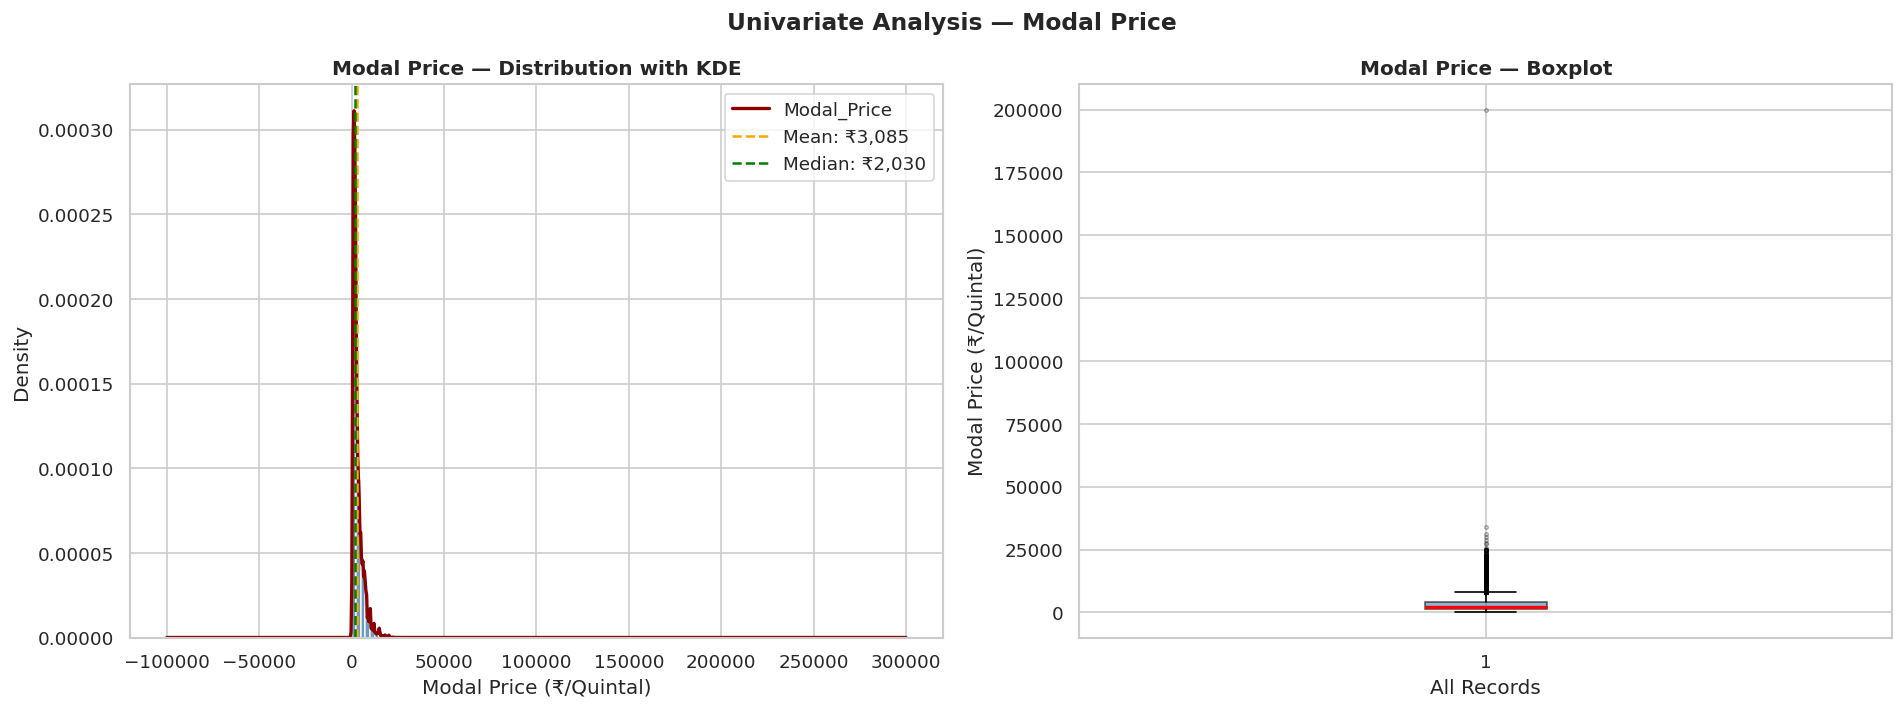


Interpretation:
- Mean Modal Price   : ₹3,085/Quintal
- Median Modal Price : ₹2,030/Quintal
- Std Deviation      : ₹2,820/Quintal
- The distribution is right-skewed, meaning a small number of
  high-value commodities pull the mean above the median.



In [16]:
# Modal Price — Overall Distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histogram with KDE
axes[0].hist(df['Modal_Price'], bins=80, color='steelblue',
             edgecolor='white', alpha=0.8, density=True)
df['Modal_Price'].plot.kde(ax=axes[0], color='darkred',
                            linewidth=2)
axes[0].set_title('Modal Price — Distribution with KDE',
                   fontweight='bold')
axes[0].set_xlabel('Modal Price (₹/Quintal)')
axes[0].set_ylabel('Density')
axes[0].axvline(df['Modal_Price'].mean(), color='orange',
                linestyle='--', linewidth=1.5,
                label=f"Mean: ₹{df['Modal_Price'].mean():,.0f}")
axes[0].axvline(df['Modal_Price'].median(), color='green',
                linestyle='--', linewidth=1.5,
                label=f"Median: ₹{df['Modal_Price'].median():,.0f}")
axes[0].legend()

# Boxplot
axes[1].boxplot(df['Modal_Price'].dropna(), vert=True,
                patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.6),
                medianprops=dict(color='red', linewidth=2),
                flierprops=dict(marker='o', markersize=2,
                                alpha=0.3, color='gray'))
axes[1].set_title('Modal Price — Boxplot', fontweight='bold')
axes[1].set_ylabel('Modal Price (₹/Quintal)')
axes[1].set_xlabel('All Records')

plt.suptitle('Univariate Analysis — Modal Price',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'univariate_modal_price.png',
            bbox_inches='tight')
plt.show()

print(f"""
Interpretation:
- Mean Modal Price   : ₹{df['Modal_Price'].mean():,.0f}/Quintal
- Median Modal Price : ₹{df['Modal_Price'].median():,.0f}/Quintal
- Std Deviation      : ₹{df['Modal_Price'].std():,.0f}/Quintal
- The distribution is right-skewed, meaning a small number of
  high-value commodities pull the mean above the median.
""")

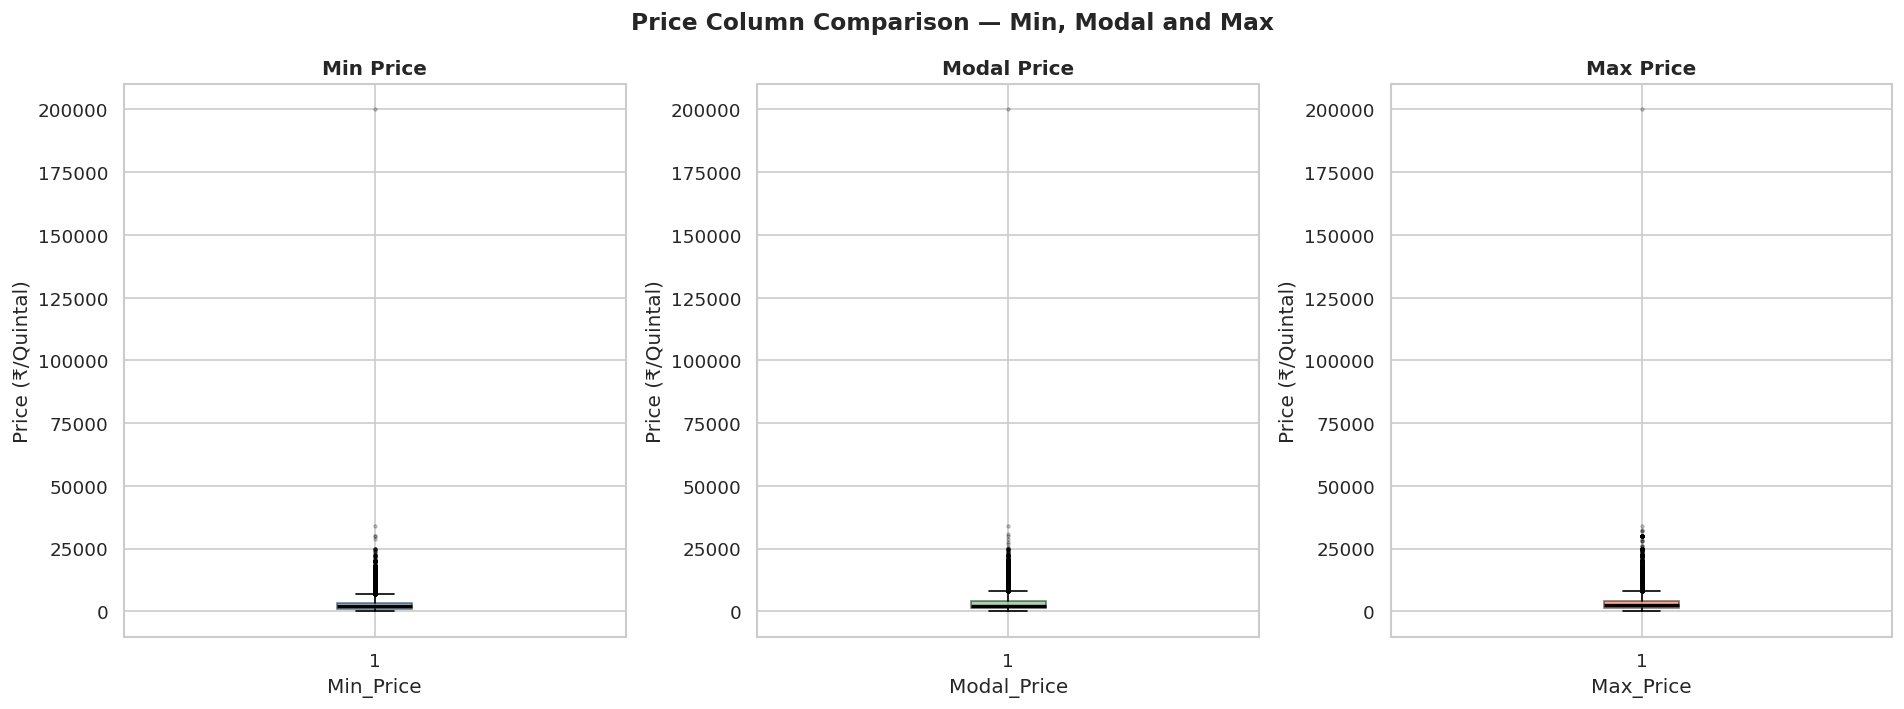


Interpretation:
All three price columns follow a similar right-skewed distribution.
Modal prices are consistently between Min and Max prices.
Outliers are present in all three columns and represent genuine
high-value market events.



In [17]:
# Min, Modal and Max Price — Boxplots
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

price_cols  = ['Min_Price', 'Modal_Price', 'Max_Price']
colors      = ['#2196F3', '#4CAF50', '#FF5722']
titles      = ['Min Price', 'Modal Price', 'Max Price']

for i, (col, color, title) in enumerate(zip(price_cols, colors, titles)):
    axes[i].boxplot(df[col].dropna(), vert=True,
                    patch_artist=True,
                    boxprops=dict(facecolor=color, alpha=0.5),
                    medianprops=dict(color='black', linewidth=2),
                    flierprops=dict(marker='o', markersize=1.5,
                                    alpha=0.3))
    axes[i].set_title(f'{title}', fontweight='bold')
    axes[i].set_ylabel('Price (₹/Quintal)')
    axes[i].set_xlabel(col)

plt.suptitle('Price Column Comparison — Min, Modal and Max',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'univariate_price_boxplots.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
All three price columns follow a similar right-skewed distribution.
Modal prices are consistently between Min and Max prices.
Outliers are present in all three columns and represent genuine
high-value market events.
""")

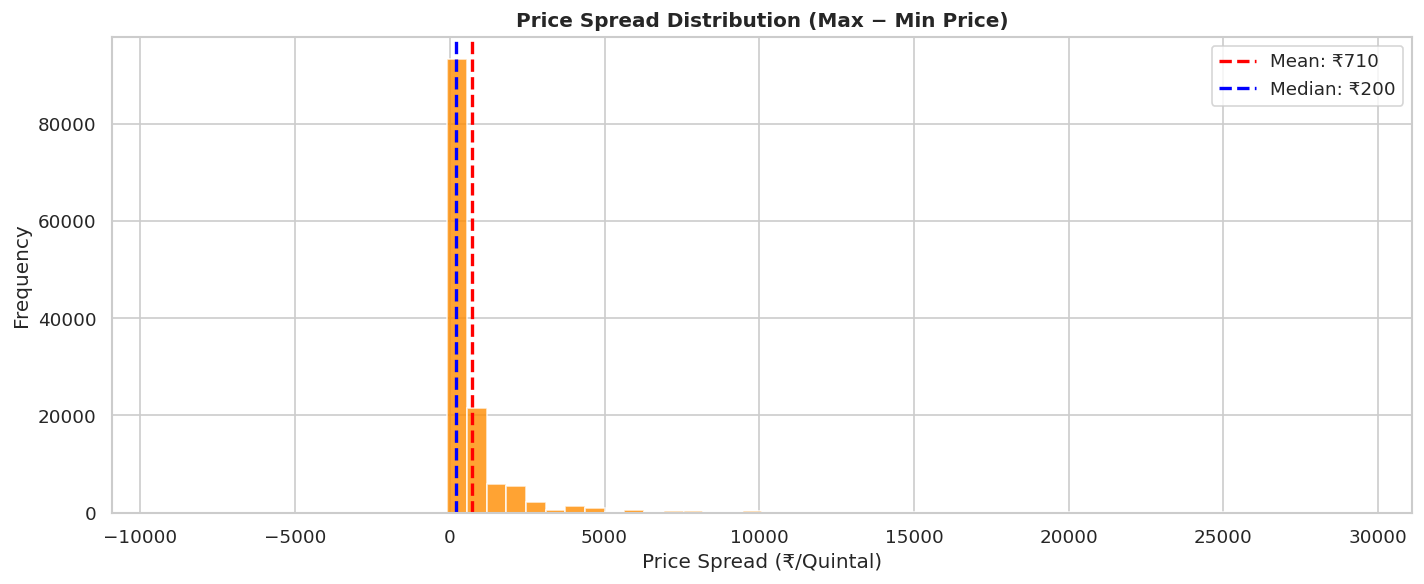


Interpretation:
- Mean Price Spread   : ₹710/Quintal
- Median Price Spread : ₹200/Quintal
- Most transactions occur within a narrow price band.
- A small number of commodity-market combinations show
  very high spreads, indicating active price negotiation.



In [18]:
# Price Spread Distribution
plt.figure(figsize=(12, 5))
plt.hist(df['Price_Spread'], bins=60, color='darkorange',
         edgecolor='white', alpha=0.8)
plt.axvline(df['Price_Spread'].mean(), color='red',
            linestyle='--', linewidth=2,
            label=f"Mean: ₹{df['Price_Spread'].mean():,.0f}")
plt.axvline(df['Price_Spread'].median(), color='blue',
            linestyle='--', linewidth=2,
            label=f"Median: ₹{df['Price_Spread'].median():,.0f}")
plt.title('Price Spread Distribution (Max − Min Price)',
          fontweight='bold')
plt.xlabel('Price Spread (₹/Quintal)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'univariate_price_spread.png',
            bbox_inches='tight')
plt.show()

print(f"""
Interpretation:
- Mean Price Spread   : ₹{df['Price_Spread'].mean():,.0f}/Quintal
- Median Price Spread : ₹{df['Price_Spread'].median():,.0f}/Quintal
- Most transactions occur within a narrow price band.
- A small number of commodity-market combinations show
  very high spreads, indicating active price negotiation.
""")

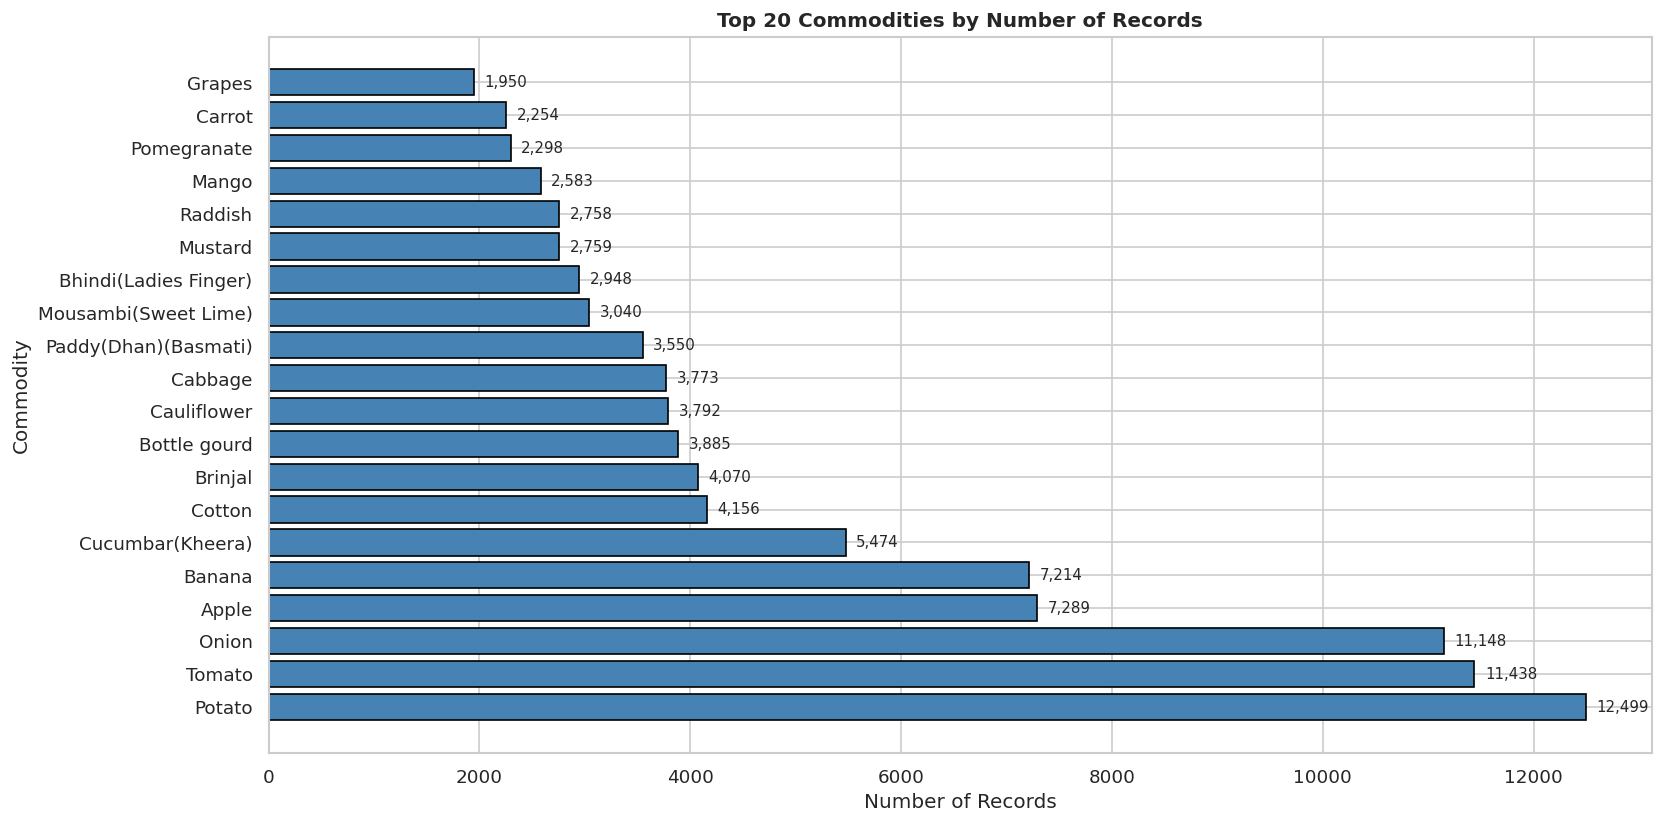


Interpretation:
The top commodities by record count represent the most actively
traded crops in Haryana mandis. Wheat, Mustard and Paddy dominate
because they are the primary Rabi and Kharif crops of the region.



In [19]:
# Commodity Frequency Distribution
top20 = df['Commodity'].value_counts().head(20).reset_index()
top20.columns = ['Commodity', 'Records']

plt.figure(figsize=(14, 7))
bars = plt.barh(top20['Commodity'], top20['Records'],
                color='steelblue', edgecolor='black')
plt.title('Top 20 Commodities by Number of Records',
          fontweight='bold')
plt.xlabel('Number of Records')
plt.ylabel('Commodity')
for bar, val in zip(bars, top20['Records']):
    plt.text(val + 100, bar.get_y() + bar.get_height()/2,
             f'{val:,}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'univariate_commodity_frequency.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
The top commodities by record count represent the most actively
traded crops in Haryana mandis. Wheat, Mustard and Paddy dominate
because they are the primary Rabi and Kharif crops of the region.
""")

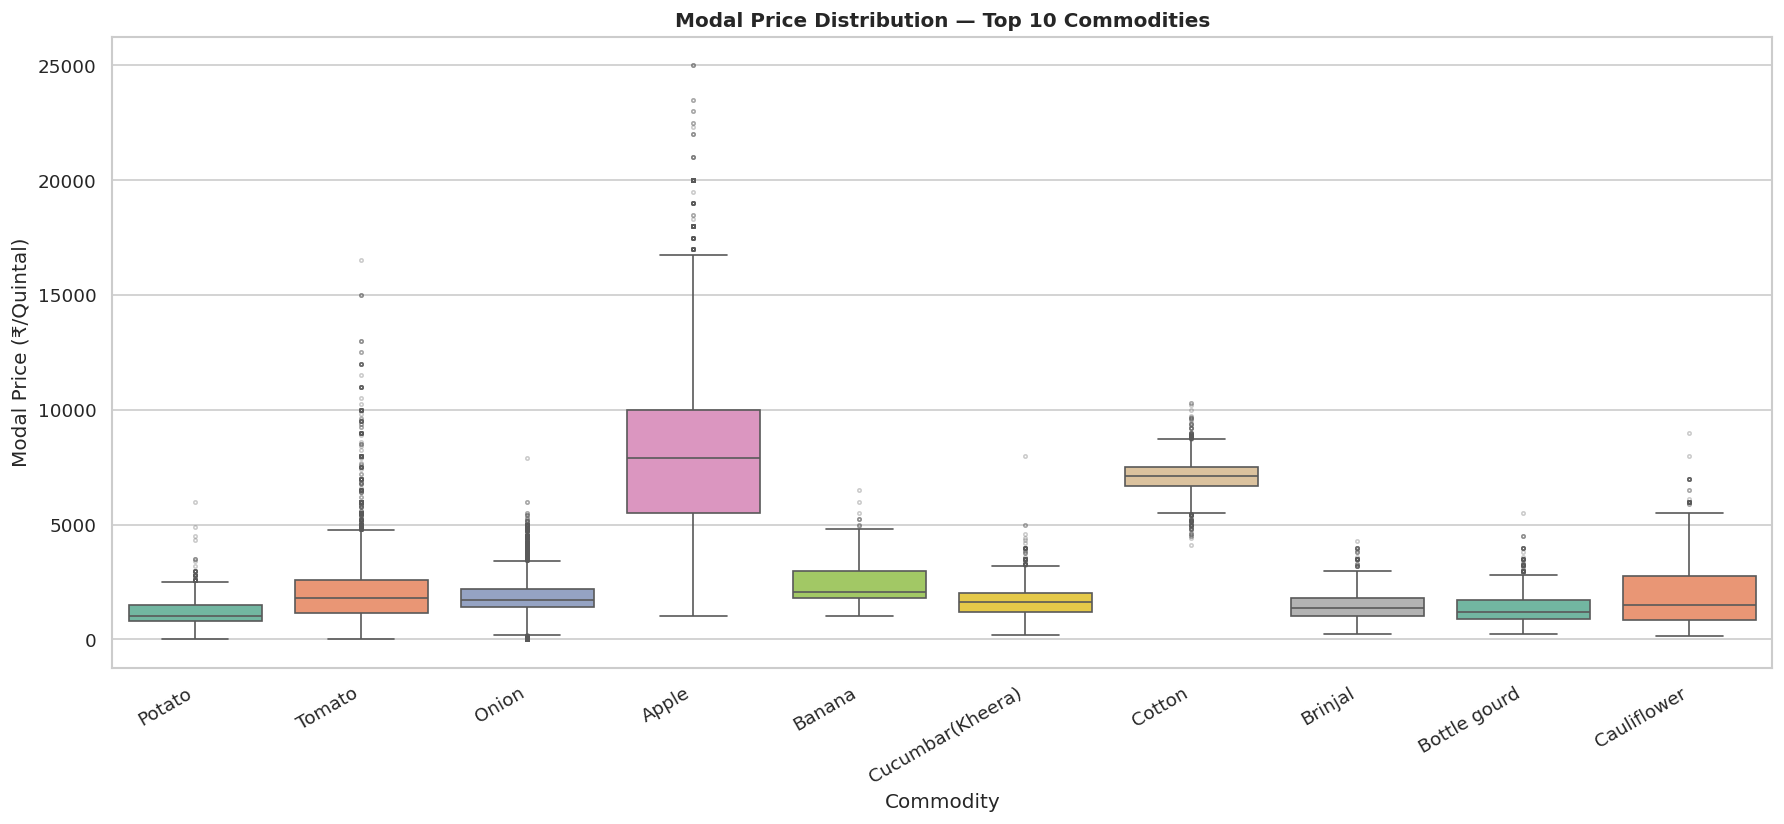


Interpretation:
Different commodities show very different price ranges and spreads.
Commodities like Cotton and Groundnut command higher prices per quintal
compared to grains like Wheat and Bajra. The wide IQR for some
commodities indicates high within-season price variability.



In [20]:
# Modal Price Distribution — Top 10 Commodities
top10 = df['Commodity'].value_counts().head(10).index.tolist()
df_top10 = df[df['Commodity'].isin(top10)]

plt.figure(figsize=(15, 7))
sns.boxplot(data=df_top10, x='Commodity', y='Modal_Price',
            order=top10, palette='Set2',
            flierprops=dict(marker='o', markersize=2, alpha=0.3))
plt.title('Modal Price Distribution — Top 10 Commodities',
          fontweight='bold')
plt.xlabel('Commodity')
plt.ylabel('Modal Price (₹/Quintal)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'univariate_top10_boxplot.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
Different commodities show very different price ranges and spreads.
Commodities like Cotton and Groundnut command higher prices per quintal
compared to grains like Wheat and Bajra. The wide IQR for some
commodities indicates high within-season price variability.
""")

## Section 4 — Bivariate Analysis

Bivariate analysis examines relationships between pairs of variables.

We examine:
- Min Price vs Modal Price
- Modal Price vs Max Price
- Min Price vs Max Price
- Price Spread vs Modal Price
- Correlation heatmap of all price variables

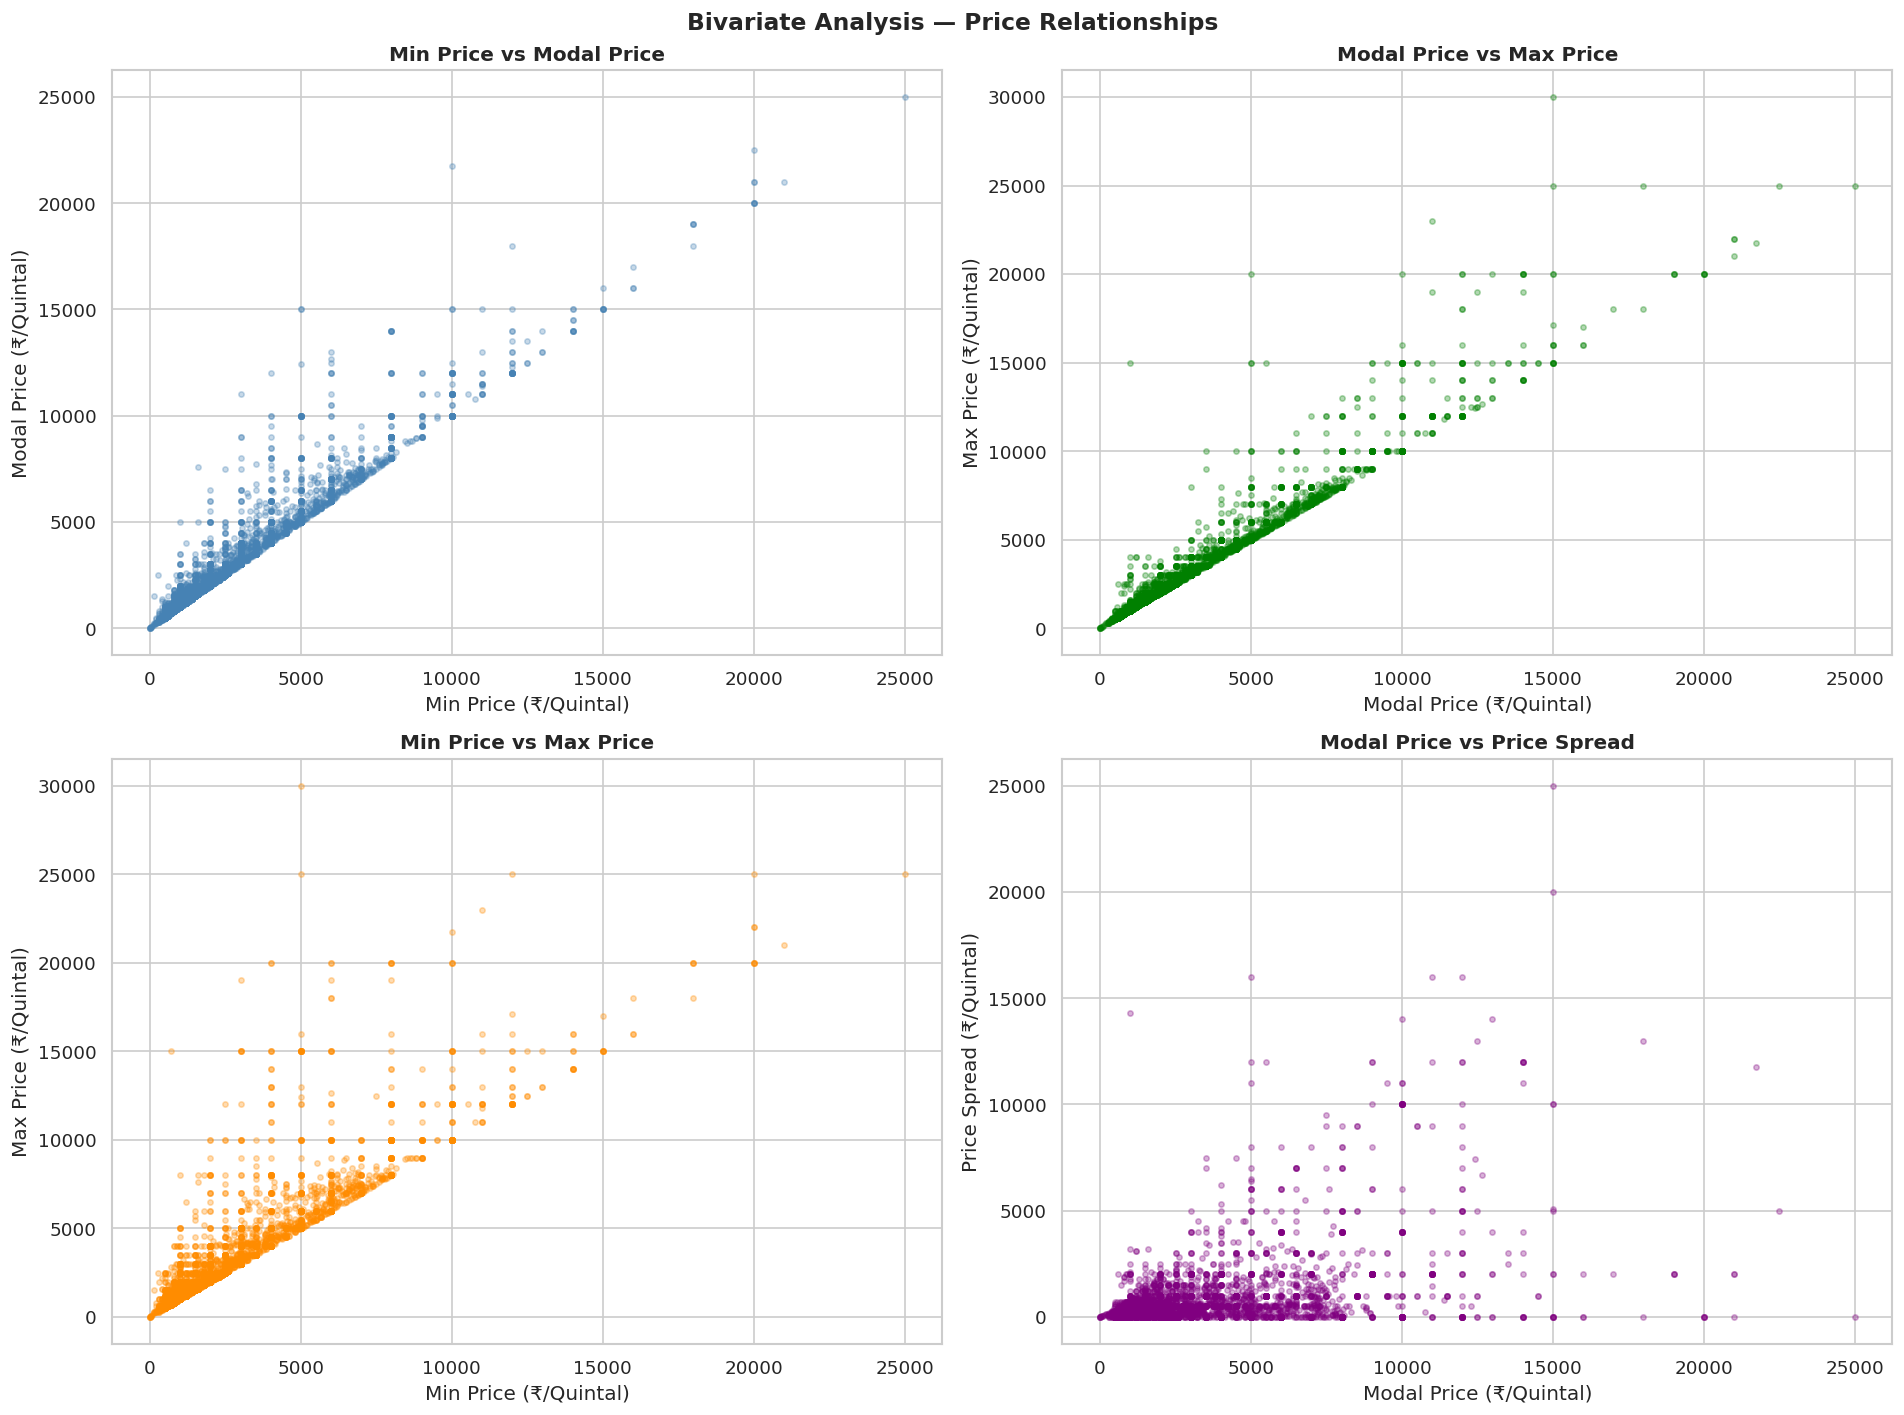


Interpretation:
- Min and Modal prices show a strong positive linear relationship,
  confirming that the modal price closely tracks the floor price.
- Modal and Max prices are similarly correlated.
- Price Spread shows higher variability at higher modal prices,
  suggesting that expensive commodities have more price negotiation.



In [21]:
# Price Column Scatter Plots
# Sample 5000 rows for scatter plot clarity
sample = df.sample(5000, random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Min vs Modal
axes[0,0].scatter(sample['Min_Price'], sample['Modal_Price'],
                  alpha=0.3, color='steelblue', s=10)
axes[0,0].set_title('Min Price vs Modal Price', fontweight='bold')
axes[0,0].set_xlabel('Min Price (₹/Quintal)')
axes[0,0].set_ylabel('Modal Price (₹/Quintal)')

# Modal vs Max
axes[0,1].scatter(sample['Modal_Price'], sample['Max_Price'],
                  alpha=0.3, color='green', s=10)
axes[0,1].set_title('Modal Price vs Max Price', fontweight='bold')
axes[0,1].set_xlabel('Modal Price (₹/Quintal)')
axes[0,1].set_ylabel('Max Price (₹/Quintal)')

# Min vs Max
axes[1,0].scatter(sample['Min_Price'], sample['Max_Price'],
                  alpha=0.3, color='darkorange', s=10)
axes[1,0].set_title('Min Price vs Max Price', fontweight='bold')
axes[1,0].set_xlabel('Min Price (₹/Quintal)')
axes[1,0].set_ylabel('Max Price (₹/Quintal)')

# Spread vs Modal
axes[1,1].scatter(sample['Modal_Price'], sample['Price_Spread'],
                  alpha=0.3, color='purple', s=10)
axes[1,1].set_title('Modal Price vs Price Spread', fontweight='bold')
axes[1,1].set_xlabel('Modal Price (₹/Quintal)')
axes[1,1].set_ylabel('Price Spread (₹/Quintal)')

plt.suptitle('Bivariate Analysis — Price Relationships',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'bivariate_scatter_plots.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
- Min and Modal prices show a strong positive linear relationship,
  confirming that the modal price closely tracks the floor price.
- Modal and Max prices are similarly correlated.
- Price Spread shows higher variability at higher modal prices,
  suggesting that expensive commodities have more price negotiation.
""")

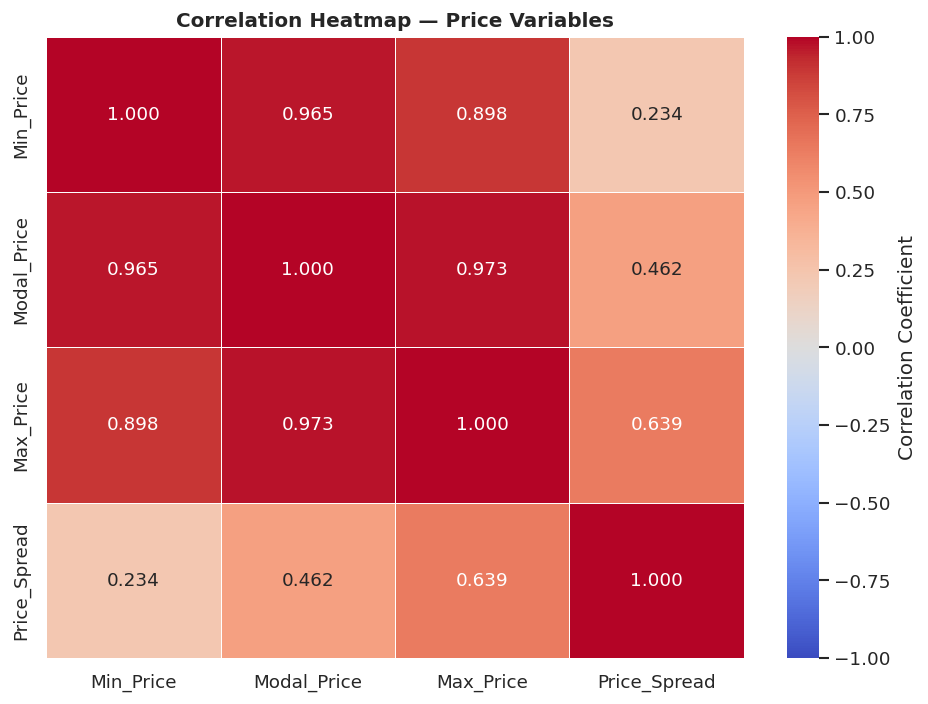


Interpretation:
- Min, Modal and Max prices are highly correlated (r > 0.95),
  which is expected as they represent the same commodity on the same day.
- Price Spread shows moderate positive correlation with all price columns,
  meaning higher priced commodities tend to have wider price ranges.
- Correlation does not imply causation.



In [22]:
# Correlation Heatmap
price_cols  = ['Min_Price', 'Modal_Price', 'Max_Price', 'Price_Spread']
corr_matrix = df[price_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.3f',
            cmap='coolwarm', linewidths=0.5,
            vmin=-1, vmax=1,
            cbar_kws={'label': 'Correlation Coefficient'})
plt.title('Correlation Heatmap — Price Variables',
          fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'bivariate_correlation_heatmap.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
- Min, Modal and Max prices are highly correlated (r > 0.95),
  which is expected as they represent the same commodity on the same day.
- Price Spread shows moderate positive correlation with all price columns,
  meaning higher priced commodities tend to have wider price ranges.
- Correlation does not imply causation.
""")

## Section 5 — Missing Value Analysis

Although Notebook 1 confirmed zero missing values in the raw dataset,
we recheck the cleaned dataset to ensure no missing values were
introduced during feature engineering.

        Column  Missing Count  Missing Pct %
  Arrival_Date              0           0.00
     Commodity              0           0.00
Commodity_Code              0           0.00
      District              0           0.00
         Grade              0           0.00
        Market              0           0.00
     Max_Price              0           0.00
     Min_Price              0           0.00
   Modal_Price              0           0.00
         State              0           0.00
       Variety              0           0.00
   Source_File              0           0.00
          Year              0           0.00
         Month              0           0.00
    Month_Name              0           0.00
       Quarter              0           0.00
          Week              0           0.00
        Season              0           0.00
  Price_Spread              0           0.00
    Is_Outlier              0           0.00


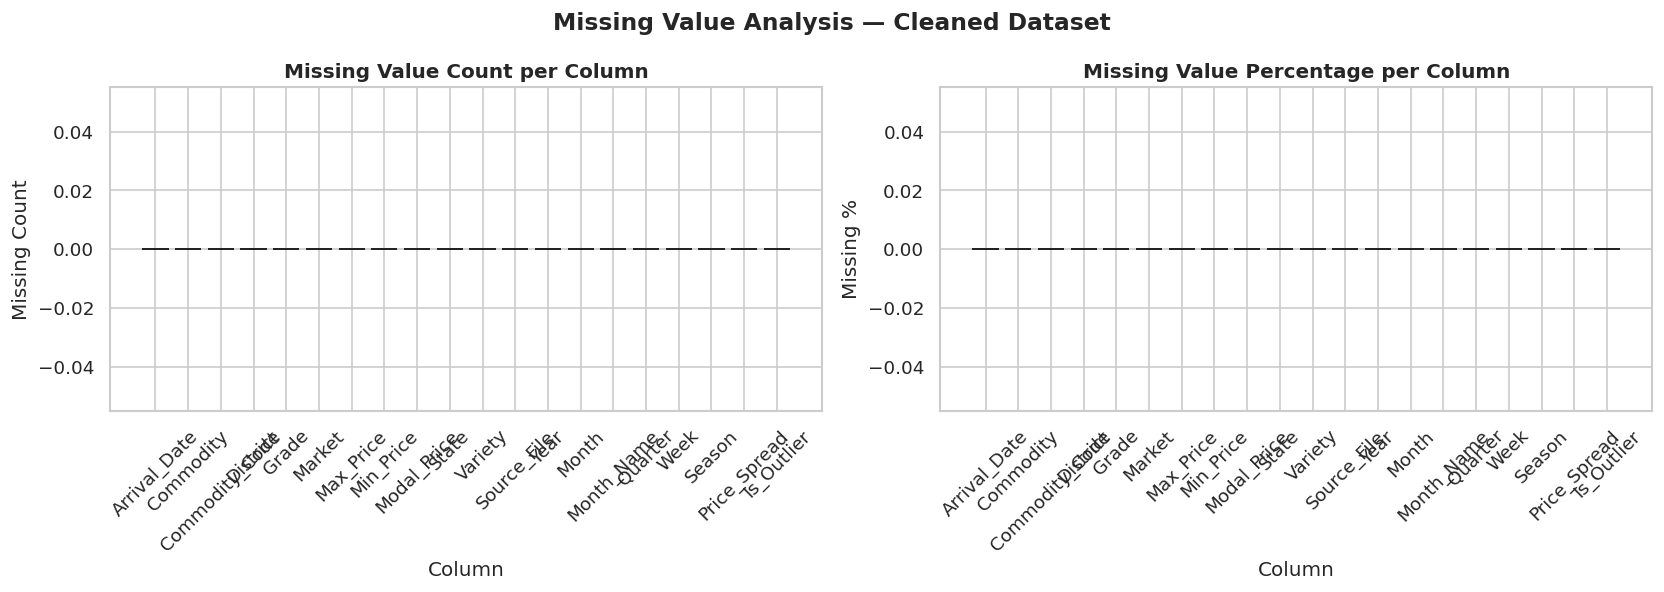

In [23]:
#  Missing Value Analysis
missing_count = df.isnull().sum()
missing_pct   = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Column'        : missing_count.index,
    'Missing Count' : missing_count.values,
    'Missing Pct %' : missing_pct.values.round(4)
}).sort_values('Missing Count', ascending=False)

print(missing_df.to_string(index=False))

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(missing_df['Column'], missing_df['Missing Count'],
            color='steelblue', edgecolor='black')
axes[0].set_title('Missing Value Count per Column',
                   fontweight='bold')
axes[0].set_xlabel('Column')
axes[0].set_ylabel('Missing Count')
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(missing_df['Column'], missing_df['Missing Pct %'],
            color='tomato', edgecolor='black')
axes[1].set_title('Missing Value Percentage per Column',
                   fontweight='bold')
axes[1].set_xlabel('Column')
axes[1].set_ylabel('Missing %')
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle('Missing Value Analysis — Cleaned Dataset',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'eda_missing_values.png',
            bbox_inches='tight')
plt.show()

## Section 6 — Outlier Analysis

We revisit the outlier flags created in Notebook 1 to understand
the distribution of outliers across commodities and their
potential impact on analysis.

In [24]:
# Outlier Summary
outlier_summary = df.groupby('Commodity').agg(
    Total    = ('Modal_Price', 'count'),
    Outliers = ('Is_Outlier',  'sum')
).reset_index()

outlier_summary['Outlier_Pct_%'] = (
    outlier_summary['Outliers'] /
    outlier_summary['Total'] * 100
).round(2)

outlier_summary = outlier_summary\
    .sort_values('Outliers', ascending=False)

print(f"Total outliers : {df['Is_Outlier'].sum():,}")
print(f"Outlier %      : {df['Is_Outlier'].mean()*100:.2f}%")
print()
print("Top 15 Commodities by Outlier Count:")
print(outlier_summary.head(15).to_string(index=False))

Total outliers : 1,036
Outlier %      : 0.77%

Top 15 Commodities by Outlier Count:
            Commodity  Total  Outliers  Outlier_Pct_%
Bhindi(Ladies Finger)   2948       216           7.33
               Tomato  11438       173           1.51
                Onion  11148       113           1.01
                Mango   2583        95           3.68
              Spinach   1302        93           7.14
               Carrot   2254        88           3.90
              Raddish   2758        34           1.23
                 Guar   1112        32           2.88
          Ginger(Dry)    170        28          16.47
 Mousambi(Sweet Lime)   3040        25           0.82
  Karbuja(Musk Melon)    694        23           3.31
        Methi(Leaves)    641        16           2.50
    Coriander(Leaves)    411        15           3.65
               Orange    781        14           1.79
         Bitter gourd   1671        10           0.60


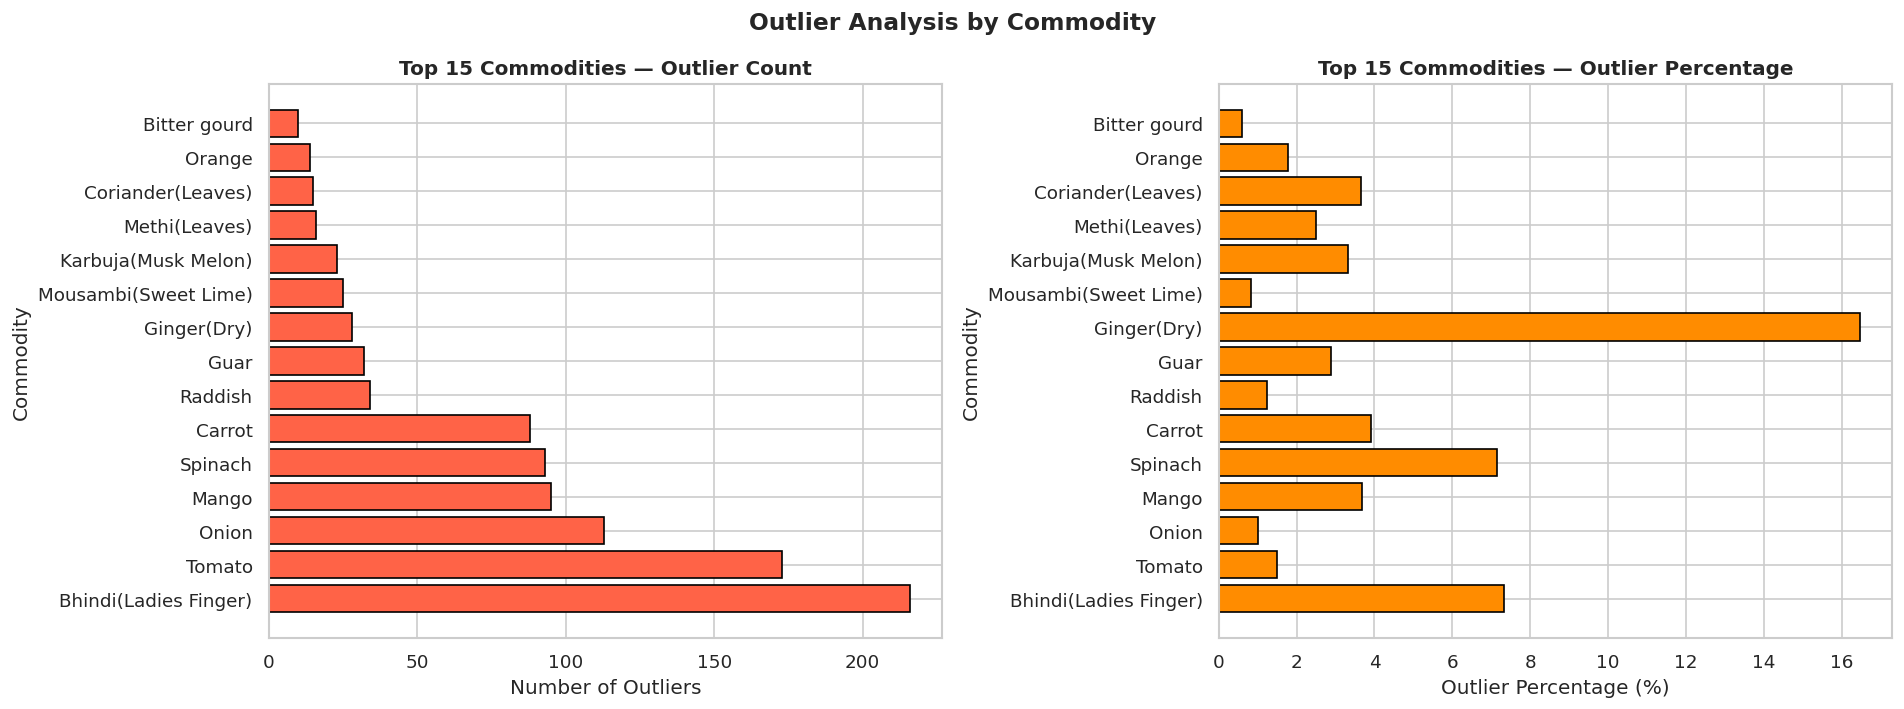


Interpretation:
Outliers are retained in the dataset as they represent
genuine market events such as crop failures, festival demand
surges and weather shocks. They are flagged for reference.



In [25]:
# Outlier Visualisation
top15_out = outlier_summary.head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(top15_out['Commodity'], top15_out['Outliers'],
             color='tomato', edgecolor='black')
axes[0].set_title('Top 15 Commodities — Outlier Count',
                   fontweight='bold')
axes[0].set_xlabel('Number of Outliers')
axes[0].set_ylabel('Commodity')

axes[1].barh(top15_out['Commodity'], top15_out['Outlier_Pct_%'],
             color='darkorange', edgecolor='black')
axes[1].set_title('Top 15 Commodities — Outlier Percentage',
                   fontweight='bold')
axes[1].set_xlabel('Outlier Percentage (%)')
axes[1].set_ylabel('Commodity')

plt.suptitle('Outlier Analysis by Commodity',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'eda_outlier_analysis.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
Outliers are retained in the dataset as they represent
genuine market events such as crop failures, festival demand
surges and weather shocks. They are flagged for reference.
""")

## Section 7 — Seasonal Analysis

Haryana's agricultural calendar is divided into three seasons:

| Season | Months | Key Crops |
|---|---|---|
| Rabi | October — March | Wheat, Mustard, Barley |
| Zaid | April — June | Watermelon, Cucumber, Muskmelon |
| Kharif | July — September | Paddy, Cotton, Bajra, Guar |

We analyse how prices vary across these seasons.

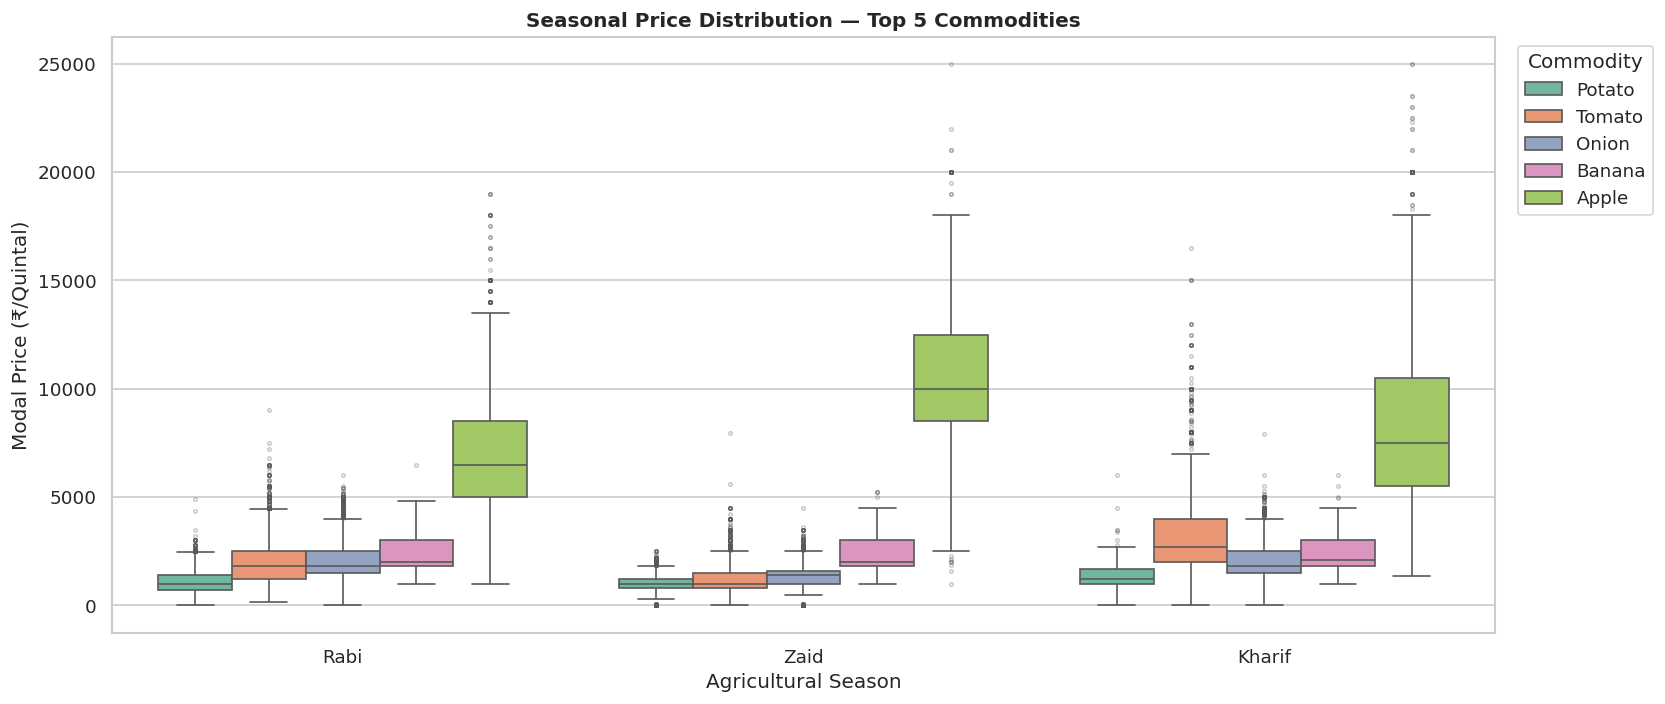

In [26]:
# Seasonal Price Boxplot
top5 = df['Commodity'].value_counts().head(5).index.tolist()

plt.figure(figsize=(14, 6))
sns.boxplot(data=df[df['Commodity'].isin(top5)],
            x='Season', y='Modal_Price',
            hue='Commodity', palette='Set2',
            order=['Rabi', 'Zaid', 'Kharif'],
            flierprops=dict(marker='o', markersize=2, alpha=0.3))
plt.title('Seasonal Price Distribution — Top 5 Commodities',
          fontweight='bold')
plt.xlabel('Agricultural Season')
plt.ylabel('Modal Price (₹/Quintal)')
plt.legend(title='Commodity', bbox_to_anchor=(1.01, 1),
           loc='upper left')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'eda_seasonal_boxplot.png',
            bbox_inches='tight')
plt.show()

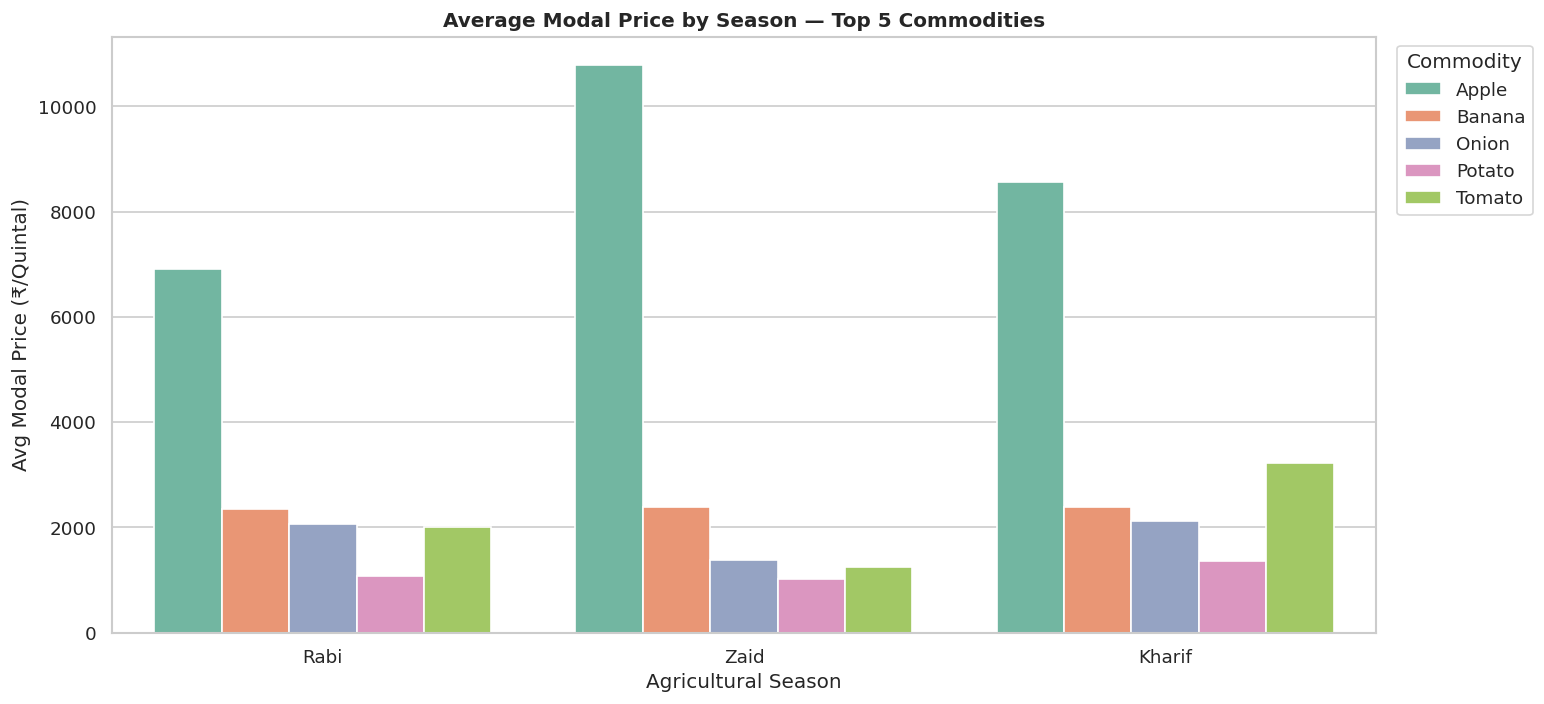


Interpretation:
Rabi crops (Wheat, Mustard) show peak prices after harvest in
April-May, as supply enters the market. Kharif crops (Paddy, Cotton)
peak in October-November. Price patterns confirm expected
post-harvest supply-demand dynamics.



In [27]:
# Seasonal Average Price Comparison
season_avg = df[df['Commodity'].isin(top5)]\
               .groupby(['Season', 'Commodity'])['Modal_Price']\
               .mean().reset_index()

plt.figure(figsize=(13, 6))
sns.barplot(data=season_avg, x='Season', y='Modal_Price',
            hue='Commodity', palette='Set2',
            order=['Rabi', 'Zaid', 'Kharif'])
plt.title('Average Modal Price by Season — Top 5 Commodities',
          fontweight='bold')
plt.xlabel('Agricultural Season')
plt.ylabel('Avg Modal Price (₹/Quintal)')
plt.legend(title='Commodity', bbox_to_anchor=(1.01, 1),
           loc='upper left')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'eda_seasonal_avg_price.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
Rabi crops (Wheat, Mustard) show peak prices after harvest in
April-May, as supply enters the market. Kharif crops (Paddy, Cotton)
peak in October-November. Price patterns confirm expected
post-harvest supply-demand dynamics.
""")

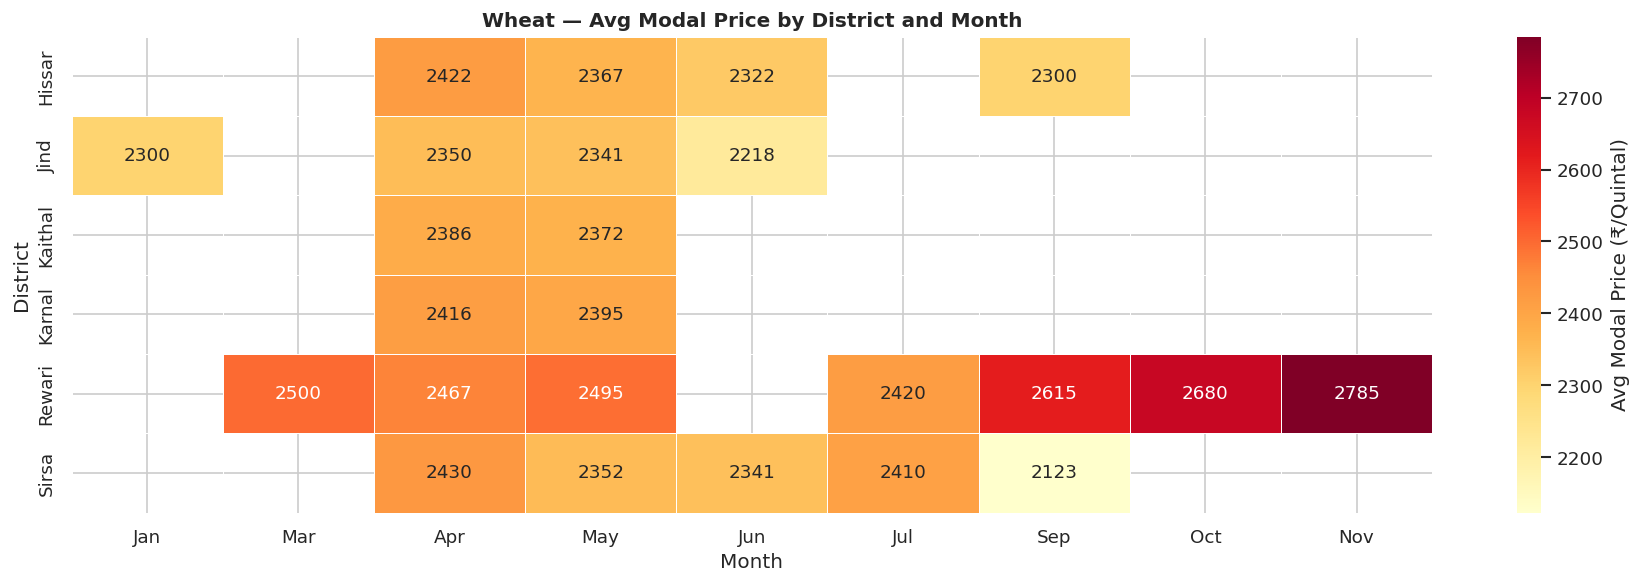


Interpretation:
Wheat prices are highest in the summer months (May-July)
after the Rabi harvest. Karnal and Kaithal consistently show
higher Wheat prices compared to other districts, likely due
to better market infrastructure and basmati rice growing areas.



In [28]:
# Monthly Price Heatmap — Wheat
month_labels = {1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr',
                5:'May', 6:'Jun', 7:'Jul', 8:'Aug',
                9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'}

wheat = df[df['Commodity'] == 'Wheat']
heatmap_data = wheat.groupby(['District', 'Month'])['Modal_Price']\
                     .mean().unstack()\
                     .rename(columns=month_labels)

plt.figure(figsize=(15, 5))
sns.heatmap(heatmap_data, annot=True, fmt='.0f',
            cmap='YlOrRd', linewidths=0.5,
            cbar_kws={'label': 'Avg Modal Price (₹/Quintal)'})
plt.title('Wheat — Avg Modal Price by District and Month',
          fontweight='bold')
plt.xlabel('Month')
plt.ylabel('District')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'eda_heatmap_wheat.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
Wheat prices are highest in the summer months (May-July)
after the Rabi harvest. Karnal and Kaithal consistently show
higher Wheat prices compared to other districts, likely due
to better market infrastructure and basmati rice growing areas.
""")

## Section 8 — District Analysis

We compare price levels, spreads and commodity availability
across the six districts: Hissar, Jind, Kaithal, Karnal,
Rewari and Sirsa.

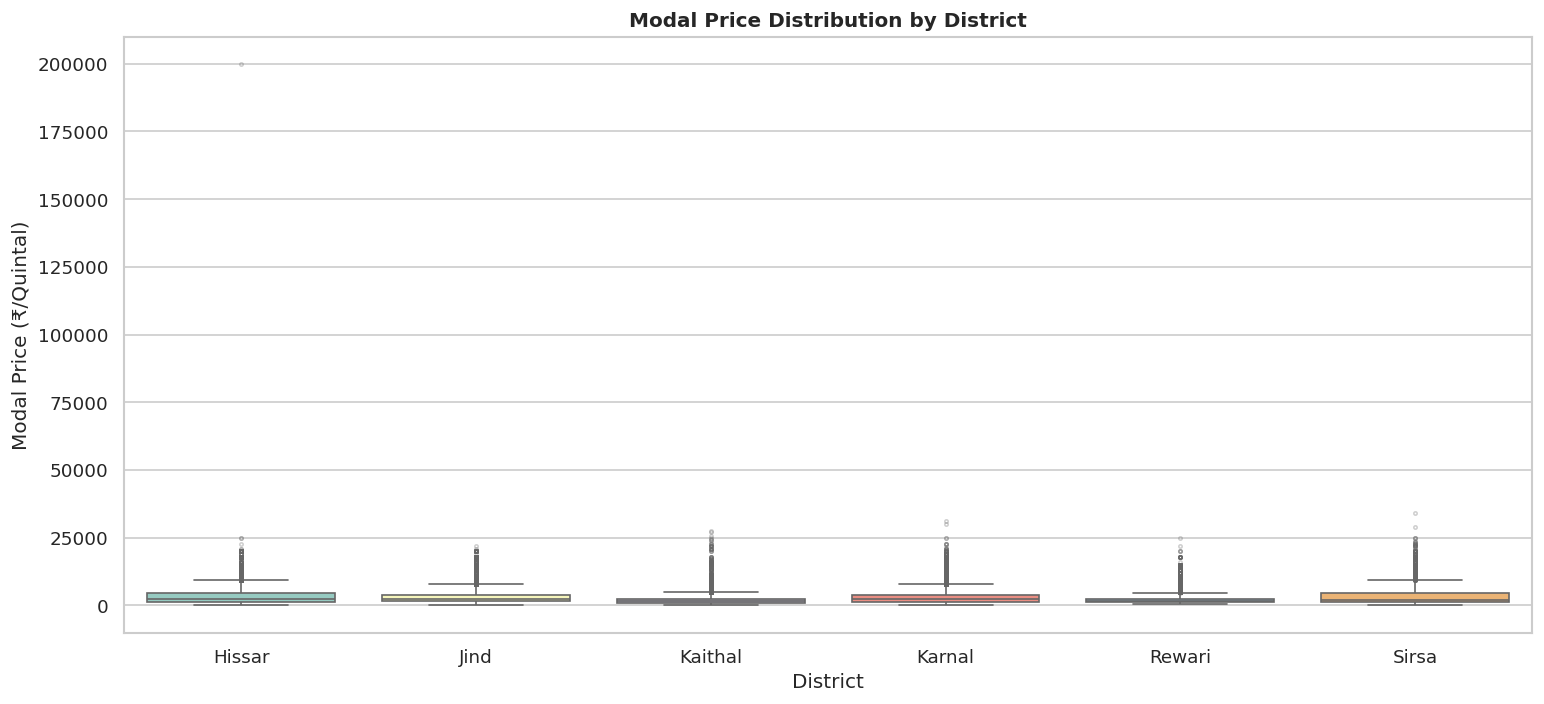


Interpretation:
All six districts show similar median modal prices, but differ
in their spread and outlier patterns. Karnal shows higher
upper-end prices, likely driven by Basmati paddy trading.



In [29]:
# District-wise Modal Price Boxplot
plt.figure(figsize=(13, 6))
sns.boxplot(data=df, x='District', y='Modal_Price',
            palette='Set3',
            order=sorted(df['District'].unique()),
            flierprops=dict(marker='o', markersize=2, alpha=0.3))
plt.title('Modal Price Distribution by District',
          fontweight='bold')
plt.xlabel('District')
plt.ylabel('Modal Price (₹/Quintal)')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'eda_district_boxplot.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
All six districts show similar median modal prices, but differ
in their spread and outlier patterns. Karnal shows higher
upper-end prices, likely driven by Basmati paddy trading.
""")

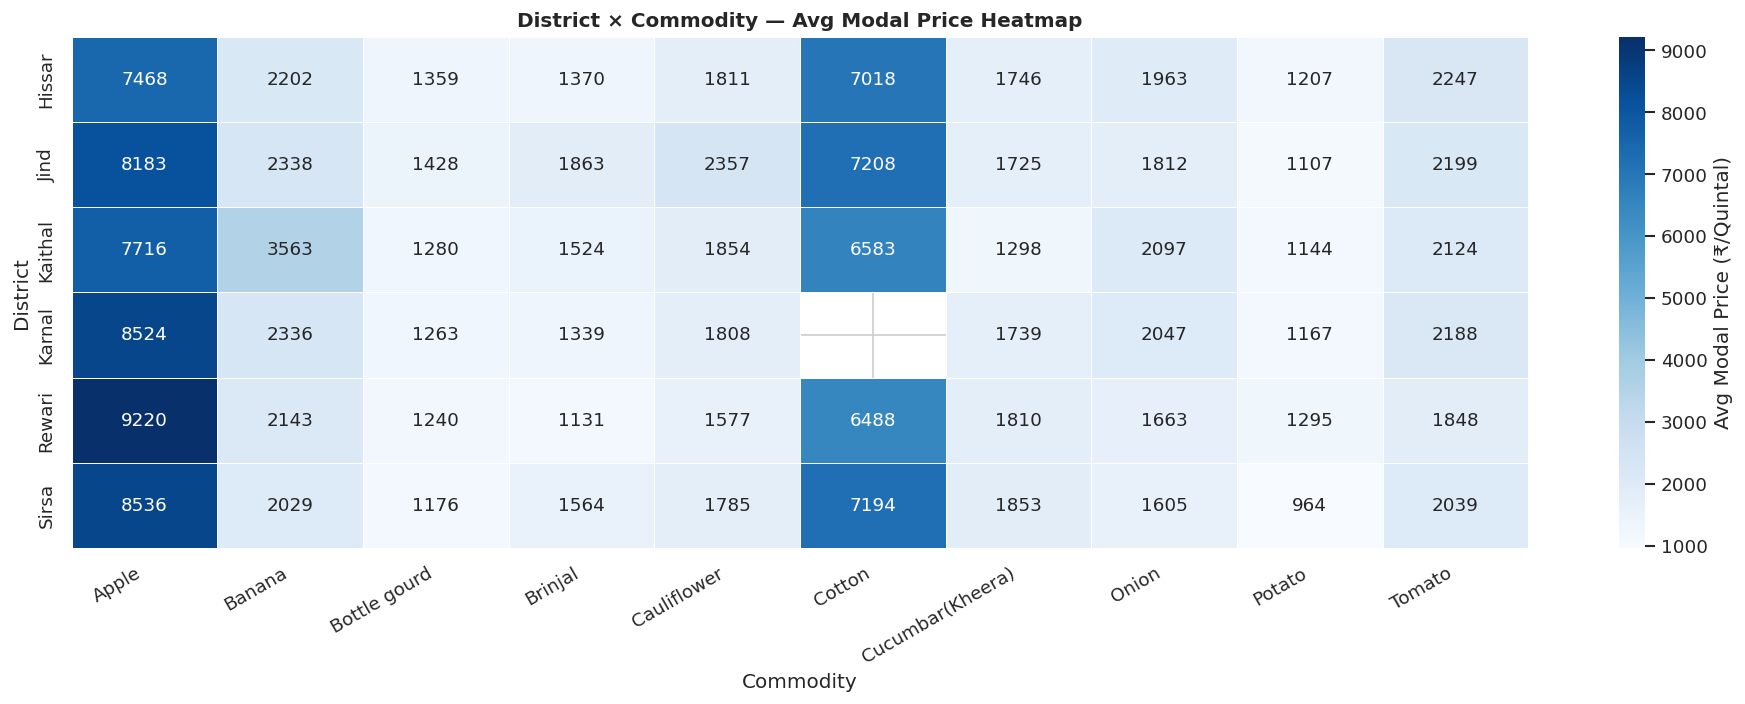


Interpretation:
The heatmap reveals which districts offer the highest average
prices for each commodity. Farmers can use this information to
choose their target market. Empty cells indicate that the
commodity is not regularly traded in that district.



In [34]:
# District × Commodity Average Price Heatmap
top10 = df['Commodity'].value_counts().head(10).index.tolist()

heatmap2 = df[df['Commodity'].isin(top10)]\
             .groupby(['District', 'Commodity'])['Modal_Price']\
             .mean().unstack().round(0)

plt.figure(figsize=(16, 6))
sns.heatmap(heatmap2, annot=True, fmt='.0f',
            cmap='Blues', linewidths=0.5,
            cbar_kws={'label': 'Avg Modal Price (₹/Quintal)'})
plt.title('District × Commodity — Avg Modal Price Heatmap',
          fontweight='bold')
plt.xlabel('Commodity')
plt.ylabel('District')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'eda_district_commodity_heatmap.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
The heatmap reveals which districts offer the highest average
prices for each commodity. Farmers can use this information to
choose their target market. Empty cells indicate that the
commodity is not regularly traded in that district.
""")

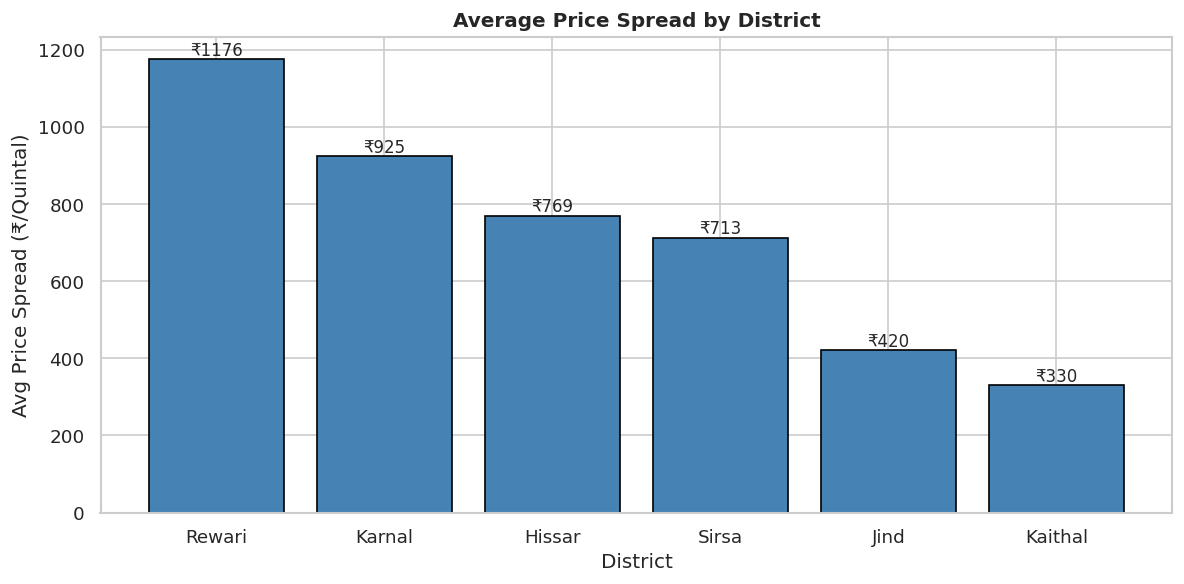


Interpretation:
Districts with higher average price spreads indicate more active
price negotiation between buyers and sellers. This can be both
an opportunity (potential to sell at higher prices) and a risk
(unpredictable price outcomes) for farmers.



In [35]:
# District-wise Price Spread
dist_spread = df.groupby('District')['Price_Spread']\
                .mean().sort_values(ascending=False).reset_index()
dist_spread.columns = ['District', 'Avg_Spread']

plt.figure(figsize=(10, 5))
bars = plt.bar(dist_spread['District'], dist_spread['Avg_Spread'],
               color='steelblue', edgecolor='black')
plt.title('Average Price Spread by District',
          fontweight='bold')
plt.xlabel('District')
plt.ylabel('Avg Price Spread (₹/Quintal)')
for bar, val in zip(bars, dist_spread['Avg_Spread']):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 10,
             f'₹{val:.0f}', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'eda_district_price_spread.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
Districts with higher average price spreads indicate more active
price negotiation between buyers and sellers. This can be both
an opportunity (potential to sell at higher prices) and a risk
(unpredictable price outcomes) for farmers.
""")

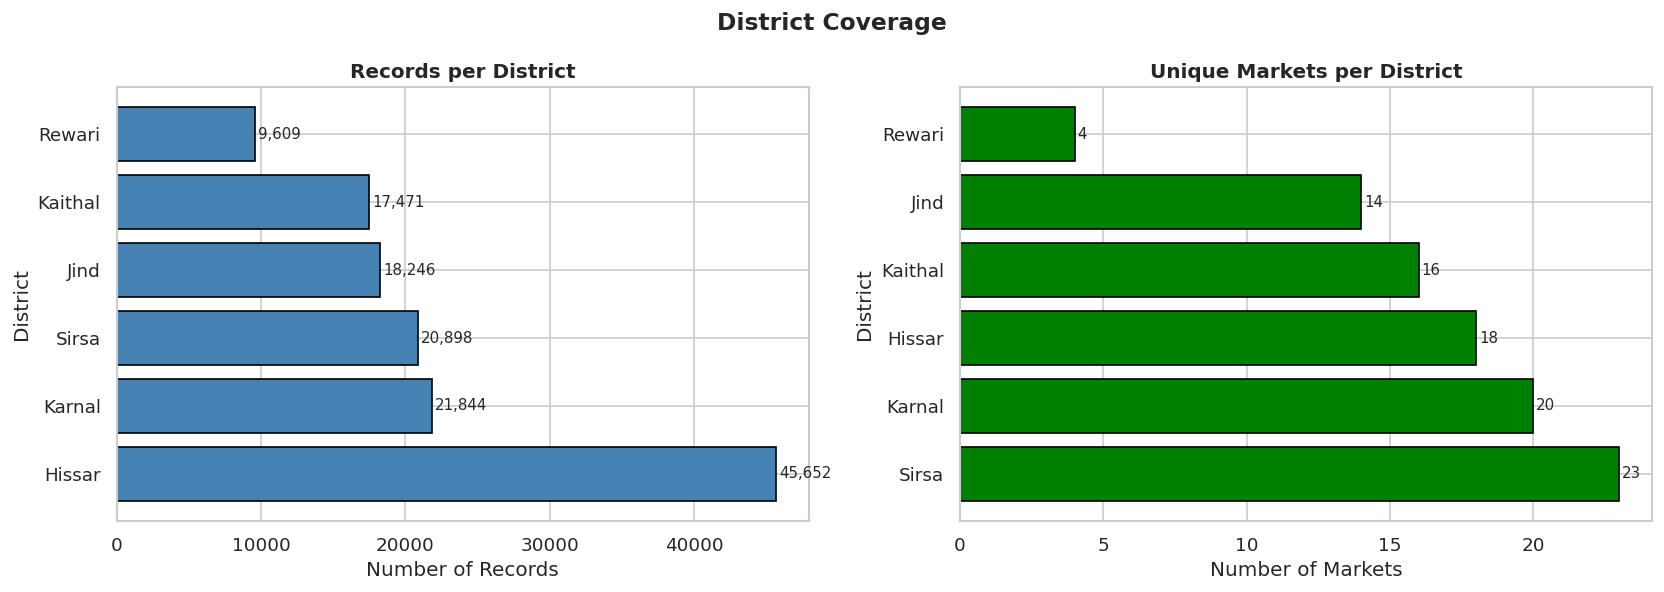

In [36]:
# District Records and Markets Coverage
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Records per district
dist_records = df['District'].value_counts().reset_index()
dist_records.columns = ['District', 'Records']
axes[0].barh(dist_records['District'], dist_records['Records'],
             color='steelblue', edgecolor='black')
axes[0].set_title('Records per District', fontweight='bold')
axes[0].set_xlabel('Number of Records')
axes[0].set_ylabel('District')
for i, v in enumerate(dist_records['Records']):
    axes[0].text(v + 200, i, f'{v:,}', va='center', fontsize=9)

# Markets per district
mkt_dist = df.groupby('District')['Market'].nunique()\
              .sort_values(ascending=False).reset_index()
mkt_dist.columns = ['District', 'Markets']
axes[1].barh(mkt_dist['District'], mkt_dist['Markets'],
             color='green', edgecolor='black')
axes[1].set_title('Unique Markets per District', fontweight='bold')
axes[1].set_xlabel('Number of Markets')
axes[1].set_ylabel('District')
for i, v in enumerate(mkt_dist['Markets']):
    axes[1].text(v + 0.1, i, str(v), va='center', fontsize=9)

plt.suptitle('District Coverage', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'eda_district_coverage.png',
            bbox_inches='tight')
plt.show()

## Section 9 — Time Series Visualisations

We examine price trends over time to identify:
- Long-term price increases or decreases
- Seasonal patterns within each year
- Year-over-year price changes
- Rolling average trends

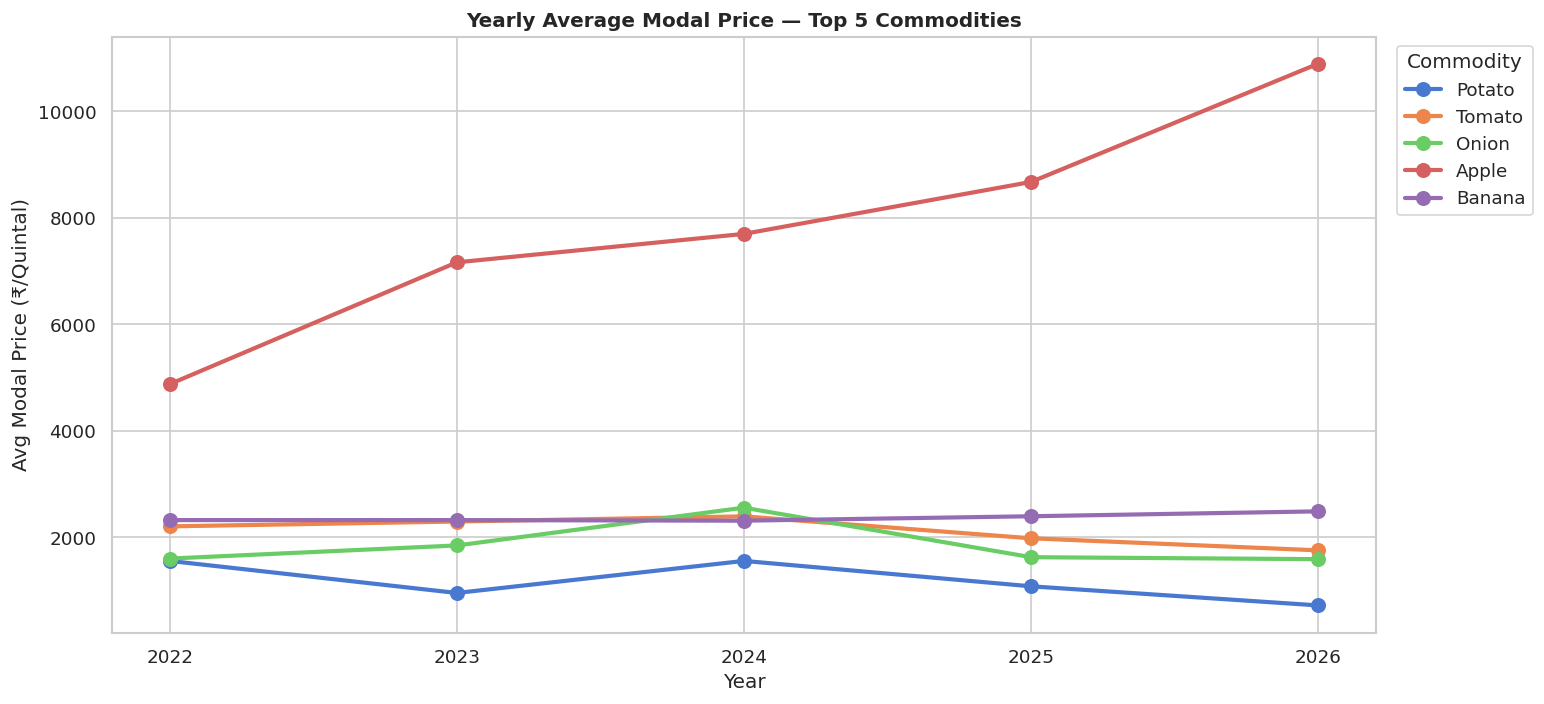


Interpretation:
Most commodities show a general upward price trend from 2022 to 2026,
consistent with national inflation trends. Cotton and Mustard show
the highest price levels, while Wheat prices remain relatively stable
due to government MSP (Minimum Support Price) intervention.



In [37]:
# Yearly Average Modal Price — Top 5 Commodities
yearly = df[df['Commodity'].isin(top5)]\
           .groupby(['Year', 'Commodity'])['Modal_Price']\
           .mean().reset_index()

plt.figure(figsize=(13, 6))
for commodity in top5:
    data = yearly[yearly['Commodity'] == commodity]
    plt.plot(data['Year'], data['Modal_Price'],
             marker='o', linewidth=2.5, markersize=8,
             label=commodity)
plt.title('Yearly Average Modal Price — Top 5 Commodities',
          fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Avg Modal Price (₹/Quintal)')
plt.xticks(yearly['Year'].unique())
plt.legend(title='Commodity', bbox_to_anchor=(1.01, 1),
           loc='upper left')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'eda_yearly_trend.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
Most commodities show a general upward price trend from 2022 to 2026,
consistent with national inflation trends. Cotton and Mustard show
the highest price levels, while Wheat prices remain relatively stable
due to government MSP (Minimum Support Price) intervention.
""")

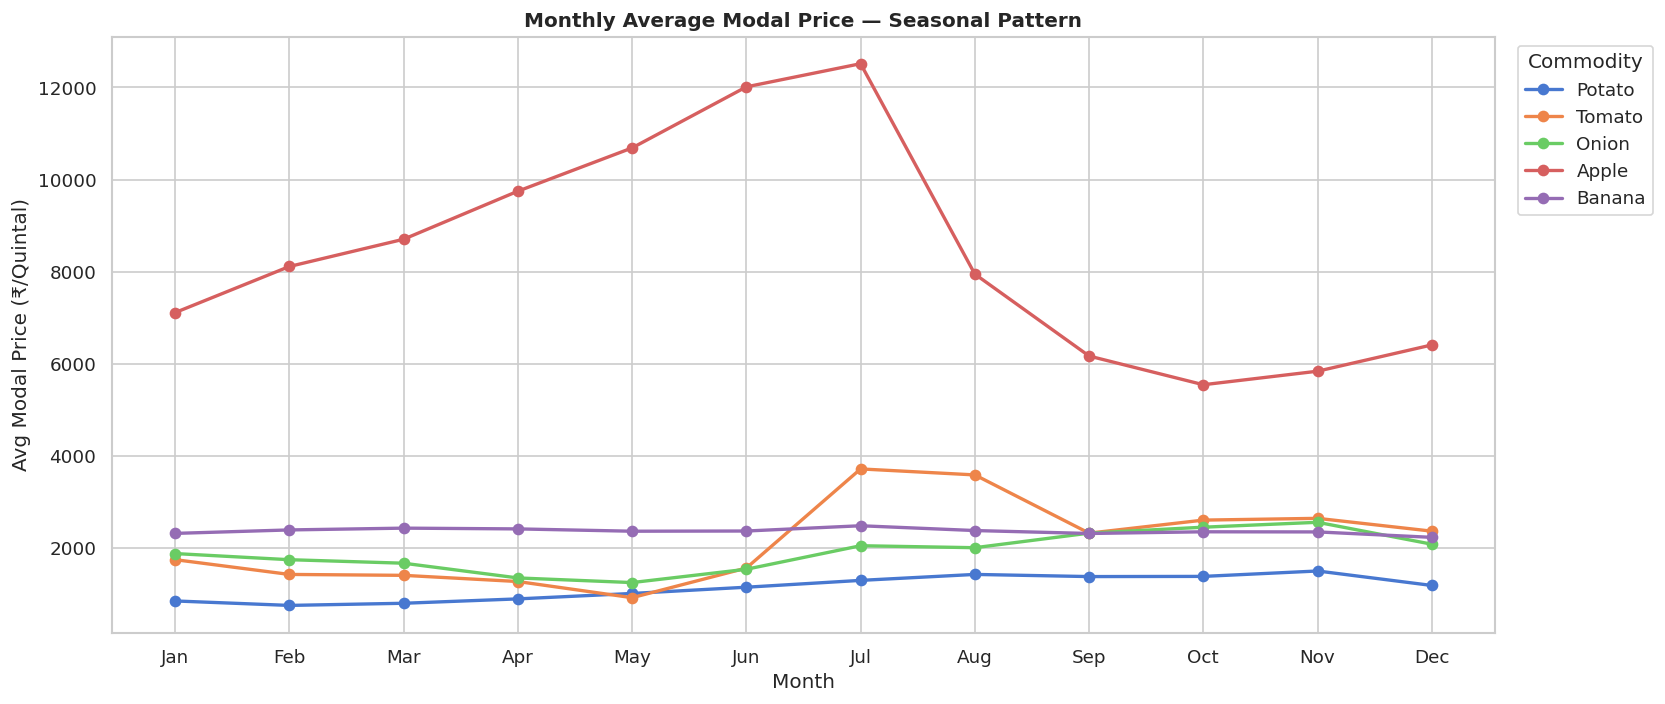


Interpretation:
Clear seasonal patterns are visible for all commodities.
Wheat prices peak in summer months after the Rabi harvest.
Cotton prices rise during the Kharif harvest period.
These patterns are critical for farmers planning when to sell.



In [38]:
# Monthly Seasonality — Top 5 Commodities
monthly_avg = df[df['Commodity'].isin(top5)]\
                .groupby(['Month', 'Commodity'])['Modal_Price']\
                .mean().reset_index()

plt.figure(figsize=(14, 6))
for commodity in top5:
    data = monthly_avg[monthly_avg['Commodity'] == commodity]
    plt.plot(data['Month'], data['Modal_Price'],
             marker='o', linewidth=2, markersize=6,
             label=commodity)
plt.xticks(range(1, 13),
           ['Jan','Feb','Mar','Apr','May','Jun',
            'Jul','Aug','Sep','Oct','Nov','Dec'])
plt.title('Monthly Average Modal Price — Seasonal Pattern',
          fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Avg Modal Price (₹/Quintal)')
plt.legend(title='Commodity', bbox_to_anchor=(1.01, 1),
           loc='upper left')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'eda_monthly_seasonality.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
Clear seasonal patterns are visible for all commodities.
Wheat prices peak in summer months after the Rabi harvest.
Cotton prices rise during the Kharif harvest period.
These patterns are critical for farmers planning when to sell.
""")

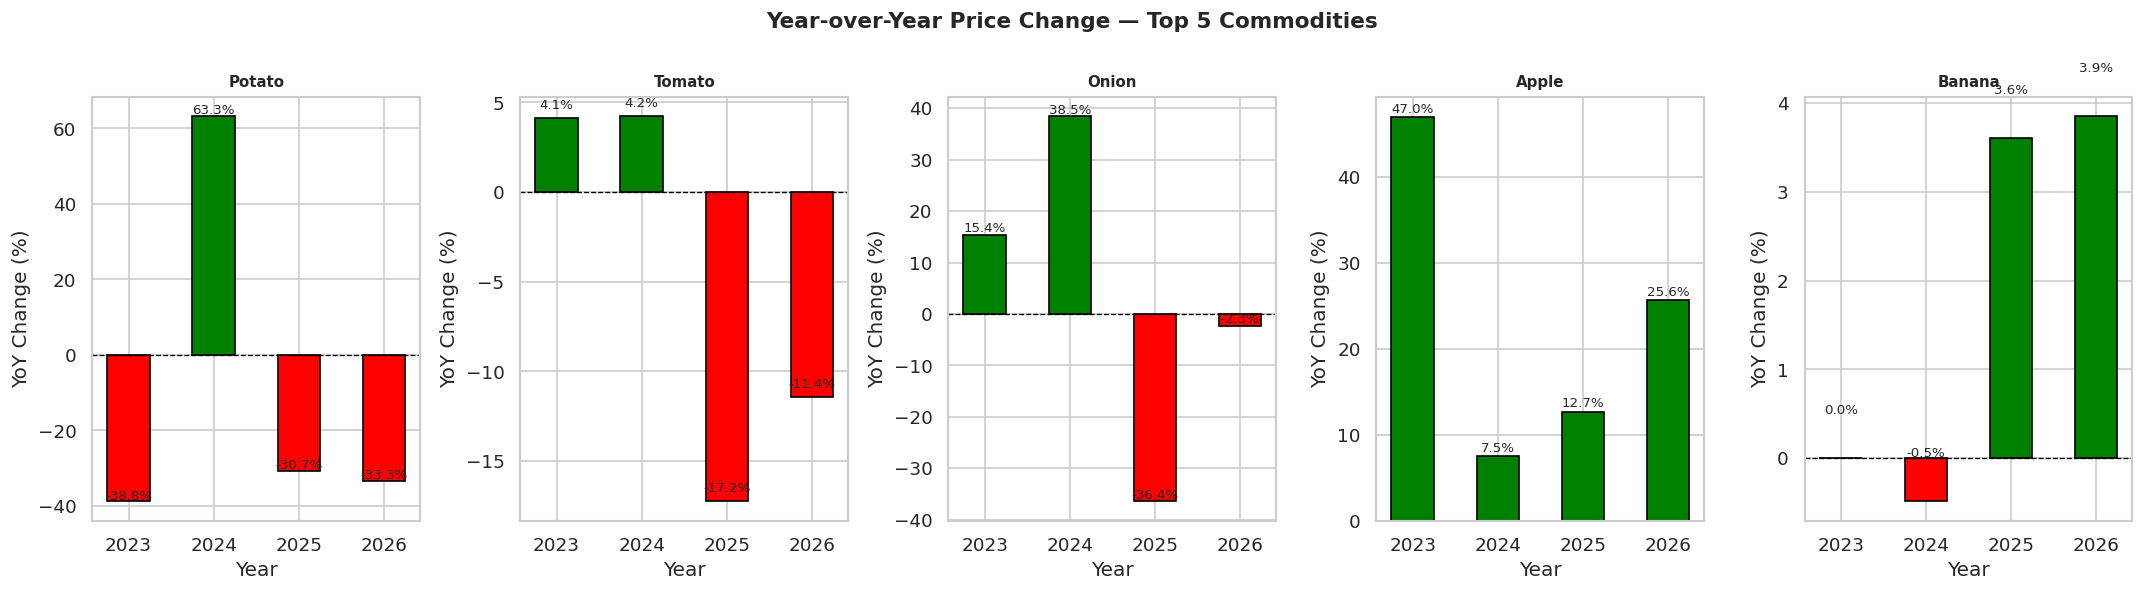

In [39]:
# Year-over-Year Price Change
yoy = df[df['Commodity'].isin(top5)]\
        .groupby(['Year', 'Commodity'])['Modal_Price']\
        .mean().reset_index()
yoy['YoY_Change_%'] = yoy.groupby('Commodity')['Modal_Price']\
                          .pct_change() * 100

fig, axes = plt.subplots(1, len(top5), figsize=(18, 5))
for i, commodity in enumerate(top5):
    data = yoy[yoy['Commodity'] == commodity].dropna()
    colors = ['green' if x >= 0 else 'red'
              for x in data['YoY_Change_%']]
    axes[i].bar(data['Year'], data['YoY_Change_%'],
                color=colors, edgecolor='black', width=0.5)
    axes[i].axhline(0, color='black', linewidth=0.8,
                    linestyle='--')
    axes[i].set_title(commodity, fontweight='bold', fontsize=9)
    axes[i].set_xlabel('Year')
    axes[i].set_ylabel('YoY Change (%)')
    for bar, val in zip(axes[i].patches, data['YoY_Change_%']):
        axes[i].text(bar.get_x() + bar.get_width()/2,
                     bar.get_height() + 0.5,
                     f'{val:.1f}%', ha='center', fontsize=8)

plt.suptitle('Year-over-Year Price Change — Top 5 Commodities',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'eda_yoy_change.png',
            bbox_inches='tight')
plt.show()

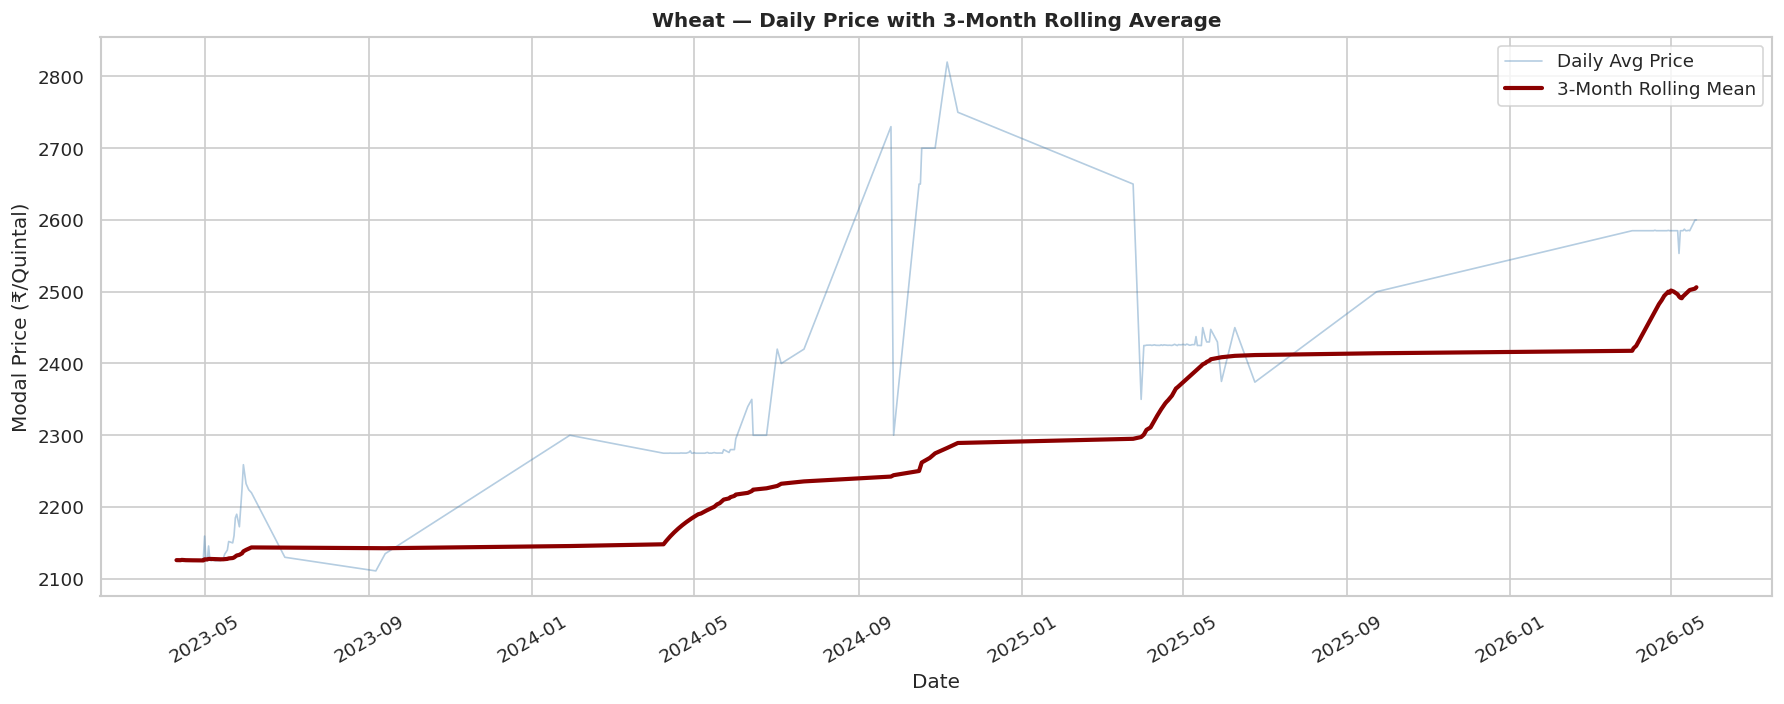


Interpretation:
The 3-month rolling average smooths out short-term price
fluctuations and reveals the underlying trend. Wheat prices
show a clear upward trend from 2022 to 2026, with a seasonal
dip after each Rabi harvest followed by gradual price recovery.



In [40]:
# Rolling Average Price Trend — Wheat
wheat_ts = df[df['Commodity'] == 'Wheat']\
             .groupby('Arrival_Date')['Modal_Price']\
             .mean().reset_index()\
             .sort_values('Arrival_Date')

wheat_ts['Roll_3M'] = wheat_ts['Modal_Price']\
                       .rolling(window=90, min_periods=1).mean()

plt.figure(figsize=(15, 6))
plt.plot(wheat_ts['Arrival_Date'], wheat_ts['Modal_Price'],
         color='steelblue', alpha=0.4, linewidth=1,
         label='Daily Avg Price')
plt.plot(wheat_ts['Arrival_Date'], wheat_ts['Roll_3M'],
         color='darkred', linewidth=2.5,
         label='3-Month Rolling Mean')
plt.title('Wheat — Daily Price with 3-Month Rolling Average',
          fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Modal Price (₹/Quintal)')
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'eda_wheat_rolling_avg.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
The 3-month rolling average smooths out short-term price
fluctuations and reveals the underlying trend. Wheat prices
show a clear upward trend from 2022 to 2026, with a seasonal
dip after each Rabi harvest followed by gradual price recovery.
""")

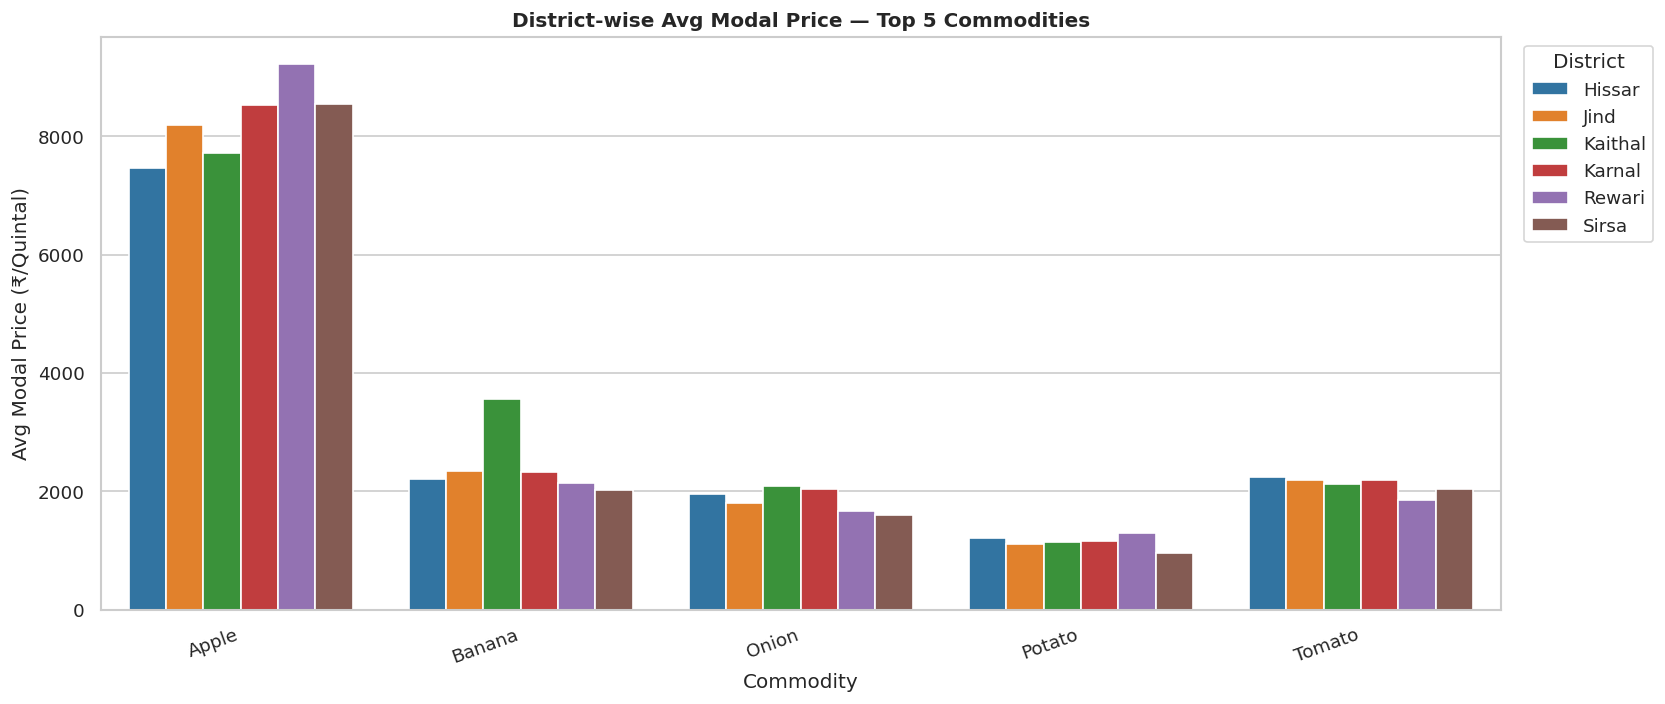

In [41]:
# District-wise Avg Modal Price — Top 5 Commodities
dist_price = df[df['Commodity'].isin(top5)]\
               .groupby(['District', 'Commodity'])['Modal_Price']\
               .mean().reset_index()

plt.figure(figsize=(14, 6))
sns.barplot(data=dist_price, x='Commodity', y='Modal_Price',
            hue='District', palette='tab10')
plt.title('District-wise Avg Modal Price — Top 5 Commodities',
          fontweight='bold')
plt.xlabel('Commodity')
plt.ylabel('Avg Modal Price (₹/Quintal)')
plt.xticks(rotation=20, ha='right')
plt.legend(title='District', bbox_to_anchor=(1.01, 1),
           loc='upper left')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'eda_district_price_comparison.png',
            bbox_inches='tight')
plt.show()

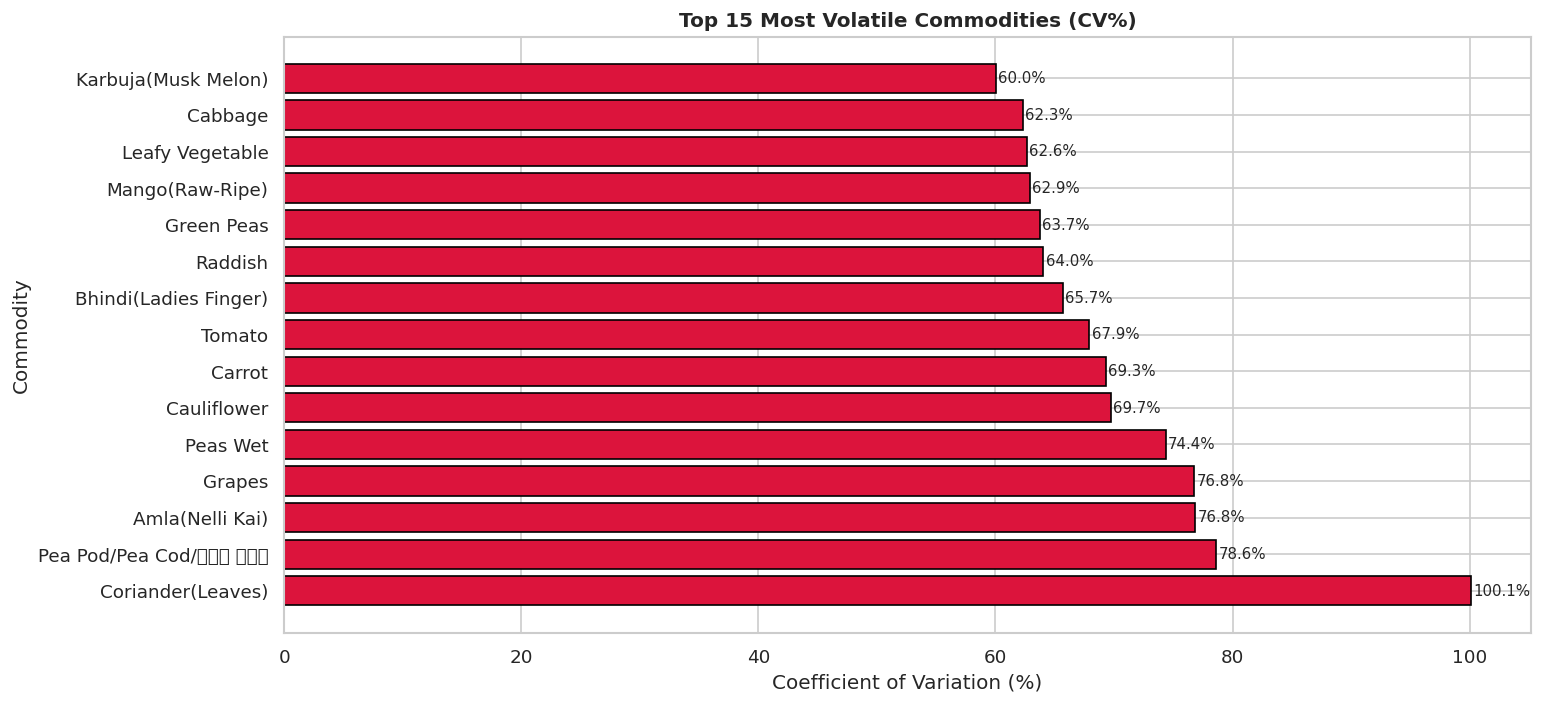


Interpretation:
High CV% indicates unpredictable prices, which increases risk
for farmers. Perishable commodities (vegetables and fruits) show
the highest volatility because supply varies significantly with
weather and seasonal demand. Grains like Wheat show lower
volatility due to MSP support.



In [42]:
# Price Volatility — Coefficient of Variation
volatility = df.groupby('Commodity')['Modal_Price']\
               .agg(['mean', 'std'])\
               .assign(CV=lambda x: (x['std'] / x['mean']) * 100)\
               .sort_values('CV', ascending=False)\
               .head(15).reset_index()

plt.figure(figsize=(13, 6))
bars = plt.barh(volatility['Commodity'], volatility['CV'],
                color='crimson', edgecolor='black')
plt.title('Top 15 Most Volatile Commodities (CV%)',
          fontweight='bold')
plt.xlabel('Coefficient of Variation (%)')
plt.ylabel('Commodity')
for bar, val in zip(bars, volatility['CV']):
    plt.text(val + 0.2, bar.get_y() + bar.get_height()/2,
             f'{val:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'eda_volatility.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
High CV% indicates unpredictable prices, which increases risk
for farmers. Perishable commodities (vegetables and fruits) show
the highest volatility because supply varies significantly with
weather and seasonal demand. Grains like Wheat show lower
volatility due to MSP support.
""")

In [44]:
# Save EDA Summary Statistics
summary_stats = df.groupby('Commodity')['Modal_Price'].agg(
    Count   = 'count',
    Mean    = 'mean',
    Median  = 'median',
    Std     = 'std',
    Min     = 'min',
    Max     = 'max'
).round(2).reset_index()

summary_stats['CV_%'] = (
    (summary_stats['Std'] / summary_stats['Mean']) * 100
).round(2)

summary_stats = summary_stats.sort_values('Count', ascending=False)
summary_stats.to_csv(PROCESSED_PATH + 'commodity_summary_stats.csv',
                     index=False)

print("Saved: commodity_summary_stats.csv")
print(summary_stats.head(10).to_string(index=False))

Saved: commodity_summary_stats.csv
       Commodity  Count    Mean  Median     Std     Min      Max  CV_%
          Potato  12499 1140.77 1000.00  494.33    0.15  6000.00 43.33
          Tomato  11438 2130.10 1800.00 1447.01    7.00 16500.00 67.93
           Onion  11148 1897.81 1700.00  876.37    0.18  7900.00 46.18
           Apple   7289 8211.28 7900.00 3501.87 1000.00 25000.00 42.65
          Banana   7214 2369.06 2050.00  717.53 1000.00  6500.00 30.29
Cucumbar(Kheera)   5474 1714.05 1650.00  651.93  200.00  8000.00 38.03
          Cotton   4156 7111.54 7125.00  696.45 4100.00 10300.00  9.79
         Brinjal   4070 1411.29 1350.00  551.63  250.00  4300.00 39.09
    Bottle gourd   3885 1323.03 1200.00  601.48  250.00  5500.00 45.46
     Cauliflower   3792 1874.93 1500.00 1307.30  150.00  9000.00 69.73
